# **Interacción Radiación-Materia — Hoja 3 de problemas**
### Detectores de radiaciones ionizantes: estadística de recuento, tiempo muerto y resolución

Este cuaderno contiene la resolución detallada de la **Hoja 3** de problemas. Cada problema incluye:

* El **enunciado**.
* La **resolución razonada** en Markdown, con las ecuaciones necesarias.
* Una celda de **cálculo en Python** que reproduce los resultados numéricos.
* En muchos casos, **simulaciones Monte Carlo** y **widgets interactivos** que permiten comprobar "experimentalmente" los resultados teóricos.

### **Preparativos**
La siguiente celda ha de ejecutarse para cargar las librerías y datos necesarios para el correcto funcionamiento de este cuaderno

In [ ]:
import os

# 1. Definir los datos del repositorio
USUARIO_GH = "nietootein"
REPOSITORIO_GH = "nirma"

# 2. Resetear siempre al directorio base ("home") de Google Colab
directorio_home = '/content'
if os.path.exists(directorio_home):
    os.chdir(directorio_home)
print(f"🏠 Partiendo del directorio de inicio: {os.getcwd()}")

# 3. Clonar el repositorio solo si no existe (y si no estamos ya dentro de él)
if os.path.basename(os.getcwd()) == REPOSITORIO_GH:
    print(f"ℹ️ Ya estamos dentro del repositorio '{REPOSITORIO_GH}'.")
elif os.path.basename(os.getcwd()) == 'notebooks' and os.path.exists('../data'):
    os.chdir('..')
    print("ℹ️ Ejecución local detectada: subiendo a la raíz del repositorio.")
else:
    if not os.path.exists(REPOSITORIO_GH):
        print(f"📦 Clonando el repositorio '{REPOSITORIO_GH}'...")
        !git clone https://github.com/{USUARIO_GH}/{REPOSITORIO_GH}.git
    else:
        print(f"ℹ️ El repositorio '{REPOSITORIO_GH}' ya está disponible en el directorio base.")
    os.chdir(REPOSITORIO_GH)
print(f"📂 Directorio de trabajo activo establecido en: {os.getcwd()}")

# 4. Importar librerías de Python
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import ipywidgets as widgets
from ipywidgets import interact
from IPython.display import display
from scipy import stats
from scipy.optimize import brentq

sns.set_theme(style='whitegrid', palette='colorblind', font='DejaVu Sans')
rng = np.random.default_rng(2025)   # generador de números aleatorios (semilla fija: resultados reproducibles)

### **Problema 1**
Empleando la fórmula asintótica de Stirling
$$ \ln(x!) \underset{x\to\infty}{=} x\ln x - x + \frac{1}{2}\ln(2\pi x) $$
demostrar que la distribución de Poisson $P(n)$ tiende a una distribución gaussiana para valores grandes de $\langle n\rangle$.

---

#### **1. Logaritmo de la distribución de Poisson**
$$ P(n) = \frac{\langle n\rangle^n}{n!}e^{-\langle n\rangle} \quad\Longrightarrow\quad \ln P(n) = n\ln\langle n\rangle - \langle n\rangle - \ln n! $$
Aplicando Stirling a $\ln n!$:
$$ \ln P(n) \approx n\ln\langle n\rangle - \langle n\rangle - n\ln n + n - \frac{1}{2}\ln(2\pi n) $$

#### **2. Desarrollo en serie alrededor de $n = \langle n\rangle$**
Cuando $\langle n\rangle \gg 1$, la distribución está concentrada en torno a su máximo, así que desarrollamos $\ln P$ hasta segundo orden en $(n - \langle n\rangle)$:
$$ \ln P(n) \approx \ln P(\langle n\rangle) + \left.\frac{d\ln P}{dn}\right|_{\langle n\rangle}(n-\langle n\rangle) + \frac{1}{2}\left.\frac{d^2\ln P}{dn^2}\right|_{\langle n\rangle}(n-\langle n\rangle)^2 $$

Los términos de la serie son:
* $\ln P(\langle n\rangle) \approx -\frac{1}{2}\ln(2\pi\langle n\rangle)$
* $\dfrac{d\ln P}{dn} = \ln\langle n\rangle - \ln n - \dfrac{1}{2n} \;\Rightarrow\; \left.\dfrac{d\ln P}{dn}\right|_{\langle n\rangle} = -\dfrac{1}{2\langle n\rangle} \xrightarrow{\langle n\rangle \gg 1} 0$
* $\dfrac{d^2\ln P}{dn^2} = -\dfrac{1}{n} + \dfrac{1}{2n^2} \;\Rightarrow\; \left.\dfrac{d^2\ln P}{dn^2}\right|_{\langle n\rangle} \approx -\dfrac{1}{\langle n\rangle}$

#### **3. Resultado**
$$ \ln P(n) \approx -\frac{1}{2}\ln(2\pi\langle n\rangle) - \frac{(n-\langle n\rangle)^2}{2\langle n\rangle} $$
$$ \boxed{P(n) \approx \frac{1}{\sqrt{2\pi\langle n\rangle}}\,\exp\left[-\frac{(n-\langle n\rangle)^2}{2\langle n\rangle}\right]} $$
que es una **gaussiana de media $\langle n\rangle$ y desviación típica $\sigma = \sqrt{\langle n\rangle}$**. $\blacksquare$

> El término lineal $-\frac{1}{2\langle n\rangle}(n - \langle n\rangle)$ desplaza ligeramente el máximo de la Poisson respecto de su media y genera la **asimetría** que se observa para valores pequeños de $\langle n\rangle$; esta asimetría desaparece como $1/\sqrt{\langle n\rangle}$.

La siguiente celda comprueba numéricamente la fórmula de Stirling y la aproximación gaussiana.

In [ ]:
from scipy.special import gammaln   # ln(x!) = gammaln(x+1), exacto

# 1. Precisión de la fórmula de Stirling
print("=====================================================================")
print("            COMPROBACIÓN DE LA FÓRMULA DE STIRLING                   ")
print("=====================================================================")
print(f"{'x':>6} | {'ln(x!) exacto':>15} | {'Stirling':>15} | {'Error relativo':>15}")
print("-" * 60)
for x in [1, 2, 5, 10, 50, 100, 1000]:
    exacto = gammaln(x + 1)
    stirling = x * np.log(x) - x + 0.5 * np.log(2 * np.pi * x)
    err = abs(stirling - exacto) / exacto if exacto > 0 else abs(stirling - exacto)
    print(f"{x:6d} | {exacto:15.6f} | {stirling:15.6f} | {err:15.2e}")
print("=====================================================================")

# 2. Poisson frente a Gauss para varios valores de <n>
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, mu in zip(axes, [2, 10, 100]):
    n = np.arange(0, int(mu + 5 * np.sqrt(mu) + 5))
    ax.bar(n, stats.poisson.pmf(n, mu), color='#4c72b0', alpha=0.6, label='Poisson')
    x = np.linspace(n[0], n[-1], 500)
    ax.plot(x, stats.norm.pdf(x, mu, np.sqrt(mu)), color='#c44e52', lw=2.5, label=r'Gauss ($\sigma=\sqrt{\langle n\rangle}$)')
    ax.set_title(f'⟨n⟩ = {mu}', fontweight='bold')
    ax.set_xlabel('n'); ax.set_ylabel('P(n)')
    ax.legend()
plt.tight_layout(); plt.show()

#### **Bonus: ¿A partir de qué $\langle n\rangle$ es buena la aproximación gaussiana?**

El widget compara la distribución de Poisson con la gaussiana de igual media y varianza, y muestra la **diferencia** entre ambas. Se indican también dos medidas de la calidad de la aproximación:
* La **asimetría** (*skewness*) de la Poisson, $\gamma_1 = 1/\sqrt{\langle n\rangle}$ (la gaussiana tiene $\gamma_1 = 0$).
* La **máxima diferencia absoluta** entre ambas distribuciones.

**Cuestiones:**
1. ¿Para qué valor de $\langle n\rangle$ la máxima diferencia cae por debajo del 1 % del valor del pico?
2. ¿Por qué la diferencia tiene siempre una forma "ondulada" característica? Relaciónalo con el término lineal despreciado en la demostración.
3. ¿Qué ocurre en $n < 0$? ¿Por qué la gaussiana nunca puede ser una descripción exacta de un recuento?

In [ ]:
def poisson_vs_gauss(mu):
    n = np.arange(0, int(mu + 6 * np.sqrt(mu) + 6))
    p = stats.poisson.pmf(n, mu)
    g = stats.norm.pdf(n, mu, np.sqrt(mu))
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
    ax = axes[0]
    ax.bar(n, p, color='#4c72b0', alpha=0.6, label='Poisson')
    x = np.linspace(min(-1, mu - 5*np.sqrt(mu)), n[-1], 600)
    ax.plot(x, stats.norm.pdf(x, mu, np.sqrt(mu)), color='#c44e52', lw=2.5, label='Gauss')
    ax.axvline(mu, color='k', ls=':', lw=1)
    ax.set_xlabel('n'); ax.set_ylabel('P(n)')
    ax.set_title(f'⟨n⟩ = {mu:.1f}', fontweight='bold'); ax.legend()
    ax = axes[1]
    ax.bar(n, (p - g) / p.max() * 100, color='#8172b3')
    ax.axhline(0, color='k', lw=0.8)
    ax.set_xlabel('n'); ax.set_ylabel('(Poisson − Gauss) / máximo  (%)')
    ax.set_title('Diferencia relativa al pico', fontweight='bold')
    plt.tight_layout(); plt.show()
    print(f"Asimetría de la Poisson: γ₁ = 1/√⟨n⟩ = {1/np.sqrt(mu):.3f}   |   "
          f"Máxima diferencia: {100*np.max(np.abs(p-g))/p.max():.2f}% del pico")

interact(poisson_vs_gauss,
         mu=widgets.FloatLogSlider(value=10, base=10, min=0, max=3, step=0.02, description='⟨n⟩',
                                   continuous_update=False));

### **Problema 2**
Demostrar que la precisión obtenida al medir la actividad de una muestra en un intervalo de tiempo $t$ es la misma que la obtenida a partir del valor medio de $N$ medidas realizadas en intervalos $t/N$.

---

#### **1. Una única medida durante un tiempo $t$**
Si se registran $n$ cuentas (variable de Poisson, $\sigma(n) = \sqrt{n}$):
$$ A = \frac{n}{t}, \qquad \sigma(A) = \frac{\sqrt{n}}{t} $$

#### **2. Una medida individual durante $t' = t/N$**
En cada intervalo se registran en promedio $n' \approx n/N$ cuentas, con $\sigma(n') = \sqrt{n/N}$:
$$ A' = \frac{n'}{t/N} = A, \qquad \sigma(A') = \frac{\sqrt{n/N}}{t/N} = \frac{\sqrt{n}}{t}\sqrt{N} $$
Cada medida individual es $\sqrt{N}$ veces **menos precisa**.

#### **3. Media de las $N$ medidas**
La actividad media es $\bar{A} = \frac{1}{N}\sum_i A_i$. Como las $N$ medidas son independientes, propagando errores:
$$ \sigma^2(\bar{A}) = \sum_{i=1}^{N}\left(\frac{\partial\bar{A}}{\partial A_i}\right)^2\sigma^2(A_i) = N\cdot\frac{1}{N^2}\,\sigma^2(A') = \frac{\sigma^2(A')}{N} $$
$$ \sigma(\bar{A}) = \frac{\sigma(A')}{\sqrt{N}} = \boxed{\frac{\sqrt{n}}{t}} = \sigma(A) \qquad \blacksquare $$

> **Consecuencia:** la precisión en la determinación de una actividad sólo depende del **número total de cuentas** registradas y del **tiempo total** de medida, no de cómo se reparta ese tiempo. Por eso se pueden sumar cuentas y tiempos de distintas medidas (ver Problema 4).

La siguiente celda lo comprueba con una **simulación Monte Carlo**: repetimos muchas veces el "experimento" de medir una fuente de actividad conocida.

In [ ]:
# =====================================================================
# SIMULACIÓN MONTE CARLO
# =====================================================================
A_true = 5.0          # actividad verdadera (s^-1)
t_total = 100.0       # tiempo total de medida (s)
N_exp = 20000         # número de experimentos simulados

def simular_estrategia(N_sub):
    # Cada experimento: N_sub medidas de t_total/N_sub segundos; se promedian las actividades
    cuentas = rng.poisson(A_true * t_total / N_sub, size=(N_exp, N_sub))
    A_i = cuentas / (t_total / N_sub)
    return A_i.mean(axis=1), A_i[:, 0]

print("=====================================================================")
print("     MONTE CARLO: UNA MEDIDA DE t FRENTE A N MEDIDAS DE t/N           ")
print("=====================================================================")
print(f"Actividad verdadera {A_true} s⁻¹, tiempo total {t_total} s  ->  σ teórica = √(A/t) = {np.sqrt(A_true/t_total):.4f} s⁻¹")
print("-" * 69)
print(f"{'N':>5} | {'σ(una medida de t/N)':>21} | {'σ(media de N medidas)':>22}")
print("-" * 69)
resultados_p2 = {}
for N_sub in [1, 2, 5, 10, 50, 100]:
    A_media, A_una = simular_estrategia(N_sub)
    resultados_p2[N_sub] = A_media
    print(f"{N_sub:5d} | {A_una.std():21.4f} | {A_media.std():22.4f}")
print("=====================================================================")

fig, ax = plt.subplots(figsize=(9, 5))
for N_sub, color in zip([1, 10, 100], ['#4c72b0', '#dd8452', '#55a868']):
    ax.hist(resultados_p2[N_sub], bins=60, histtype='step', lw=2, density=True, color=color,
            label=f'Media de {N_sub} medidas de {t_total/N_sub:g} s')
ax.set_xlabel('Actividad estimada (s⁻¹)'); ax.set_ylabel('Densidad de probabilidad')
ax.set_title('Las tres estrategias tienen la misma dispersión', fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()

### **Problema 3**
Con un contador Geiger se hace una medida en la que se detectan 200 desintegraciones en 100 segundos.

**a)** Hallar la actividad de la muestra y su incertidumbre.

**b)** Se realiza a continuación una medida de 1 segundo. ¿Cuál es la probabilidad de no observar ninguna desintegración en ese periodo? ¿Cuál es el número de desintegraciones para el que la probabilidad es máxima?

**c)** ¿Cuál es la probabilidad de volver a observar 200 desintegraciones en otra medida de 100 s?

**d)** ¿Durante cuánto tiempo sería necesario medir para poder determinar la actividad relativa de la muestra con una incertidumbre inferior al 0,1 %?

---

#### **a) Actividad e incertidumbre**
$$ A = \frac{200 \pm \sqrt{200}}{100\text{ s}} = \mathbf{(2.00 \pm 0.14)\text{ s}^{-1}} $$

#### **b) Medida de 1 segundo**
El número medio de cuentas esperado en $t = 1$ s es $\langle n\rangle = A\,t = 2.00$. Con la distribución de Poisson $P(n) = \frac{\langle n\rangle^n}{n!}e^{-\langle n\rangle}$:
$$ P(0) = e^{-2} = \mathbf{0.135}\;(13.5\%) $$
$$ P(1) = 2e^{-2} = 0.271, \qquad P(2) = \frac{2^2}{2!}e^{-2} = 0.271, \qquad P(3) = \frac{2^3}{3!}e^{-2} = 0.180 $$
La probabilidad es máxima, con el **mismo valor (27 %)**, para **$n = 1$ y $n = 2$**. (Para una Poisson con $\langle n\rangle$ entero, siempre hay dos modas: $\langle n\rangle$ y $\langle n\rangle - 1$.)

#### **c) Probabilidad de volver a observar 200 cuentas en 100 s**
Ahora $\langle n\rangle = 200$:
$$ P(200) = \frac{200^{200}}{200!}e^{-200} $$
Este número no se puede evaluar directamente con una calculadora, pero usando Stirling (Problema 1) con $n = \langle n\rangle$:
$$ \ln P(200) \approx -\frac{1}{2}\ln(2\pi\cdot200) = -3.57 \quad\Rightarrow\quad P(200) \approx \frac{1}{\sqrt{2\pi\cdot200}} = \mathbf{0.028}\;(2.8\%) $$
¡Aunque 200 es el valor más probable, la probabilidad de repetirlo exactamente es sólo del 2.8 %!

#### **d) Tiempo necesario para una incertidumbre relativa del 0.1 %**
La incertidumbre relativa en $A$ es la misma que en $n$:
$$ \varepsilon_r = \frac{\sqrt{n}}{n} = \frac{1}{\sqrt{n}} = 10^{-3} \quad\Rightarrow\quad n = 10^6 \text{ cuentas} $$
$$ t = \frac{n}{A} = \frac{10^6}{2.00\text{ s}^{-1}} = 5.0\times10^5\text{ s} \approx \mathbf{140\text{ h}} \;(\approx 5.8\text{ días}) $$
Como $A$ sólo se conoce con un 7 % de incertidumbre, la estimación del tiempo tiene una incertidumbre $\Delta t = \frac{n}{A^2}\Delta A = 0.35\times10^5$ s $\approx 10$ h.

In [ ]:
# =====================================================================
# 1. DATOS DE ENTRADA
# =====================================================================
n_p3, t_p3 = 200, 100.0

# =====================================================================
# 2. CÁLCULOS
# =====================================================================
A_p3 = n_p3 / t_p3
sA_p3 = np.sqrt(n_p3) / t_p3

mu_1s = A_p3 * 1.0
P_b = stats.poisson.pmf(np.arange(6), mu_1s)

P_200_exacta = stats.poisson.pmf(200, 200)
P_200_stirling = 1 / np.sqrt(2 * np.pi * 200)

n_d = 1 / 1e-3**2
t_d = n_d / A_p3
dt_d = n_d / A_p3**2 * sA_p3

# =====================================================================
# 3. IMPRESIÓN DE RESULTADOS
# =====================================================================
print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 3)                    ")
print("=====================================================================")
print(f"a) A = ({A_p3:.2f} ± {sA_p3:.2f}) s⁻¹   (incertidumbre relativa {100*sA_p3/A_p3:.1f}%)")
print("-" * 69)
print(f"b) ⟨n⟩ en 1 s = {mu_1s:.2f}")
for k, p in enumerate(P_b):
    print(f"   P({k}) = {p:.4f}  ({100*p:.1f}%)")
print("-" * 69)
print(f"c) P(200 | ⟨n⟩=200): exacta = {P_200_exacta:.5f},  Stirling = {P_200_stirling:.5f}")
print("-" * 69)
print(f"d) n necesario = {n_d:.0e} cuentas  ->  t = {t_d:.2e} s = {t_d/3600:.0f} h  (± {dt_d/3600:.0f} h)")
print("=====================================================================")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
ax = axes[0]
n = np.arange(0, 10)
barras = ax.bar(n, stats.poisson.pmf(n, mu_1s), color=['#c44e52' if k in (1, 2) else '#4c72b0' for k in n])
ax.bar_label(barras, fmt='%.3f', fontsize=8)
ax.set_xlabel('n (cuentas en 1 s)'); ax.set_ylabel('P(n)')
ax.set_title('b) Poisson con ⟨n⟩ = 2', fontweight='bold')
ax = axes[1]
n = np.arange(140, 261)
ax.bar(n, stats.poisson.pmf(n, 200), color='#4c72b0', alpha=0.7)
ax.bar([200], [P_200_exacta], color='#c44e52')
ax.set_xlabel('n (cuentas en 100 s)'); ax.set_ylabel('P(n)')
ax.set_title(f'c) Poisson con ⟨n⟩ = 200:  P(200) = {100*P_200_exacta:.1f}%', fontweight='bold')
plt.tight_layout(); plt.show()

### **Problema 4**
Con un contador sin tiempo muerto se detectan 23 partículas de una fuente poissoniana en un intervalo de 35 segundos.

**a)** Hallar la actividad y su error. ¿Cuál es la probabilidad de registrar en una medida posterior otra vez 23 partículas en el mismo tiempo?

**b)** Se realiza una segunda medida y se detectan 300 partículas en 350 segundos. Usando todos estos datos recalcular la actividad de la fuente y su error. ¿Cuál es la probabilidad de registrar en una medida posterior de 35 segundos 23 partículas? ¿Y la de registrar 30 partículas?

---

#### **a) Primera medida**
$$ A = \frac{23 \pm \sqrt{23}}{35\text{ s}} = \mathbf{(0.66 \pm 0.14)\text{ s}^{-1}} $$
Nuestra mejor estimación del número medio de cuentas en 35 s es $\langle n\rangle = 23$:
$$ P(23\,|\,\langle n\rangle = 23) = \frac{23^{23}}{23!}e^{-23} = \mathbf{0.083}\;(8.3\%) $$
(Stirling daría $1/\sqrt{2\pi\cdot 23} = 0.083$, ya muy preciso).

#### **b) Combinación de las dos medidas**
Como vimos en el Problema 2, la precisión sólo depende del número total de cuentas y del tiempo total, así que **sumamos cuentas y tiempos**:
$$ A = \frac{323 \pm \sqrt{323}}{385\text{ s}} = \mathbf{(0.839 \pm 0.047)\text{ s}^{-1}} $$
Ahora el número medio esperado en 35 s es $\langle n\rangle = A\cdot t = 0.839\times35 = 29.4$:
$$ P(23\,|\,29.4) = \frac{29.4^{23}}{23!}e^{-29.4} = \mathbf{0.039}\;(3.9\%), \qquad P(30\,|\,29.4) = \frac{29.4^{30}}{30!}e^{-29.4} = \mathbf{0.072}\;(7.2\%) $$

> Observa que el resultado de la primera medida (0.66 ± 0.14 s⁻¹) es compatible con el combinado (0.84 ± 0.05 s⁻¹) a $1.3\sigma$: con sólo 23 cuentas, la primera medida fluctuó hacia abajo.

#### **Justificación: el método de máxima verosimilitud**
¿Por qué es correcto sumar cuentas y tiempos? Si la actividad es $A$, la probabilidad de observar $n_1$ cuentas en $t_1$ **y** $n_2$ cuentas en $t_2$ es el producto:
$$ \mathcal{L}(A) = P(n_1, n_2; A) = \frac{(At_1)^{n_1}}{n_1!}e^{-At_1}\,\frac{(At_2)^{n_2}}{n_2!}e^{-At_2} = K\,A^{n}e^{-At}, \qquad n = n_1+n_2,\; t = t_1+t_2 $$
El **método de máxima verosimilitud** (R. A. Fisher, 1922) toma como mejor estimación de $A$ el valor que maximiza la probabilidad de haber observado lo que hemos observado:
$$ \frac{d\mathcal{L}}{dA} = \left(\frac{n}{A} - t\right)K A^n e^{-At} = 0 \quad\Longrightarrow\quad \hat{A} = \frac{n}{t} = \frac{n_1+n_2}{t_1+t_2} $$
Además, la anchura de la función de verosimilitud ($-2\Delta\ln\mathcal{L} = 1$) proporciona la incertidumbre, $\sigma(\hat{A}) \approx \sqrt{n}/t$.

In [ ]:
# =====================================================================
# 1. DATOS DE ENTRADA
# =====================================================================
n1, t1 = 23, 35.0
n2, t2 = 300, 350.0

# =====================================================================
# 2. CÁLCULOS
# =====================================================================
A1, sA1 = n1 / t1, np.sqrt(n1) / t1
P_23_a = stats.poisson.pmf(23, n1)

n_tot, t_tot = n1 + n2, t1 + t2
A_comb, sA_comb = n_tot / t_tot, np.sqrt(n_tot) / t_tot
mu_35 = A_comb * 35.0
P_23_b = stats.poisson.pmf(23, mu_35)
P_30_b = stats.poisson.pmf(30, mu_35)

# =====================================================================
# 3. IMPRESIÓN DE RESULTADOS
# =====================================================================
print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 4)                    ")
print("=====================================================================")
print(f"a) A = ({A1:.3f} ± {sA1:.3f}) s⁻¹")
print(f"   P(23 | ⟨n⟩=23) = {P_23_a:.4f}  ({100*P_23_a:.1f}%)")
print("-" * 69)
print(f"b) A combinada = ({A_comb:.3f} ± {sA_comb:.3f}) s⁻¹")
print(f"   ⟨n⟩ en 35 s = {mu_35:.2f}")
print(f"   P(23 | {mu_35:.1f}) = {P_23_b:.4f}  ({100*P_23_b:.1f}%)")
print(f"   P(30 | {mu_35:.1f}) = {P_30_b:.4f}  ({100*P_30_b:.1f}%)")
print("=====================================================================")

# =====================================================================
# 4. FUNCIONES DE VEROSIMILITUD
# =====================================================================
A_grid = np.linspace(0.2, 1.4, 1000)
def logL(A, n, t):
    return n * np.log(A * t) - A * t      # salvo constantes
fig, ax = plt.subplots(figsize=(10, 5.5))
for (n, t, etiqueta, color) in [(n1, t1, 'Medida 1: 23 cuentas en 35 s', '#4c72b0'),
                                 (n2, t2, 'Medida 2: 300 cuentas en 350 s', '#55a868'),
                                 (n_tot, t_tot, 'Combinada: 323 cuentas en 385 s', '#c44e52')]:
    L = np.exp(logL(A_grid, n, t) - logL(n / t, n, t))
    ax.plot(A_grid, L, color=color, lw=2.5, label=etiqueta)
    ax.axvline(n / t, color=color, ls=':', lw=1)
ax.axhline(np.exp(-0.5), color='gray', ls='--', lw=1)
ax.text(1.2, np.exp(-0.5) + 0.02, r'$\mathcal{L}_{max}\,e^{-1/2}$ → ±1σ', color='gray')
ax.set_xlabel('Actividad A (s⁻¹)'); ax.set_ylabel(r'$\mathcal{L}(A)/\mathcal{L}_{max}$')
ax.set_title('Funciones de verosimilitud de las medidas', fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()

### **Problema 5**
Con un contador se detectan 12150 desintegraciones en 10 minutos. En una medida del fondo se observan 2350 cuentas en un intervalo de 5 minutos.

**a)** Hallar la actividad de la muestra y su error.

**b)** Durante cuánto tiempo $t$ habría que medir para reducir el error al 1 % con una medida de fondo de $t/2$.

---

#### **a) Actividad neta**
* **Total (muestra + fondo):** $A_T = \dfrac{12150 \pm \sqrt{12150}}{600\text{ s}} = (20.25 \pm 0.18)\text{ s}^{-1}$
* **Fondo:** $A_F = \dfrac{2350 \pm \sqrt{2350}}{300\text{ s}} = (7.83 \pm 0.16)\text{ s}^{-1}$

La actividad de la muestra es la diferencia, y los errores (independientes) se suman en cuadratura:
$$ A = 20.25 - 7.83 = 12.42\text{ s}^{-1}, \qquad \sigma(A) = \sqrt{0.18^2 + 0.16^2} = 0.24\text{ s}^{-1} $$
$$ \boxed{A = (12.42 \pm 0.24)\text{ s}^{-1}} \quad (\approx 2\%) $$

#### **b) Tiempo necesario para un error del 1 %**
Con un tiempo $t$ para la medida total y $t/2$ para el fondo:
$$ A = \frac{n_T}{t} - \frac{n_F}{t/2}, \qquad \sigma^2(A) = \frac{\sigma^2(n_T)}{t^2} + \frac{\sigma^2(n_F)}{(t/2)^2} $$
con $\sigma^2(n_T) = n_T = A_T\,t$ y $\sigma^2(n_F) = n_F = A_F\,t/2$:
$$ \sigma^2(A) = \frac{A_T}{t} + \frac{2A_F}{t} = \frac{20.25 + 15.67}{t} = \frac{35.9\text{ s}^{-1}}{t} $$
$$ \frac{\sigma(A)}{A} = \frac{1}{12.42}\sqrt{\frac{35.9}{t}} = 0.01 \quad\Rightarrow\quad t = \frac{35.9}{(0.01\times12.42)^2} \approx 2330\text{ s} \approx \mathbf{39\text{ min}} $$
(y otros 19.5 min de medida de fondo).

In [ ]:
# =====================================================================
# 1. DATOS DE ENTRADA
# =====================================================================
nT, tT = 12150, 600.0
nF, tF = 2350, 300.0
objetivo = 0.01

# =====================================================================
# 2. CÁLCULOS
# =====================================================================
AT, sAT = nT / tT, np.sqrt(nT) / tT
AF, sAF = nF / tF, np.sqrt(nF) / tF
A_p5 = AT - AF
sA_p5 = np.hypot(sAT, sAF)

coef = AT + 2 * AF                      # σ²(A)·t  (s^-1)
t_p5 = coef / (objetivo * A_p5)**2

# =====================================================================
# 3. IMPRESIÓN DE RESULTADOS
# =====================================================================
print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 5)                    ")
print("=====================================================================")
print(f"a) Total: ({AT:.2f} ± {sAT:.2f}) s⁻¹   Fondo: ({AF:.2f} ± {sAF:.2f}) s⁻¹")
print(f"   Actividad neta: A = ({A_p5:.2f} ± {sA_p5:.2f}) s⁻¹   ({100*sA_p5/A_p5:.1f}%)")
print("-" * 69)
print(f"b) σ²(A)·t = {coef:.1f} s⁻¹   ->   t = {t_p5:.0f} s = {t_p5/60:.1f} min (fondo: {t_p5/120:.1f} min)")
print("=====================================================================")

#### **Bonus: ¿Cuál es el mejor reparto del tiempo entre muestra y fondo?**

En el apartado b) el reparto del tiempo (fondo = mitad del tiempo de la medida total) venía impuesto. Pero si disponemos de un **tiempo total fijo** $T = t_T + t_F$, ¿cómo conviene repartirlo? Minimizando $\sigma^2(A) = A_T/t_T + A_F/t_F$ con $t_T + t_F = T$ se obtiene el resultado clásico:
$$ \frac{t_F}{t_T} = \sqrt{\frac{A_F}{A_T}} $$

**Cuestiones:**
1. Para los datos del problema, ¿qué fracción del tiempo total debería dedicarse al fondo? ¿Era muy mala la elección $t_F = t_T/2$?
2. ¿Qué ocurre cuando el fondo es mucho menor que la señal? ¿Y cuando la muestra es muy débil ($A \ll A_F$)?

In [ ]:
def reparto_tiempo(A_muestra, A_fondo, T_total_min):
    T = T_total_min * 60
    A_tot = A_muestra + A_fondo
    f = np.linspace(0.01, 0.99, 500)                  # fracción del tiempo dedicada al fondo
    sigma = np.sqrt(A_tot / ((1 - f) * T) + A_fondo / (f * T))
    f_opt = np.sqrt(A_fondo / A_tot) / (1 + np.sqrt(A_fondo / A_tot))
    s_opt = np.sqrt(A_tot / ((1 - f_opt) * T) + A_fondo / (f_opt * T))
    s_13 = np.sqrt(A_tot / ((2/3) * T) + A_fondo / ((1/3) * T))

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(f, 100 * sigma / A_muestra, color='#4c72b0', lw=2.5)
    ax.plot(f_opt, 100 * s_opt / A_muestra, '*', color='gold', ms=18, mec='k',
            label=f'Óptimo: t_F/T = {f_opt:.2f}  (σ/A = {100*s_opt/A_muestra:.2f}%)')
    ax.plot(1/3, 100 * s_13 / A_muestra, 'o', color='#c44e52', ms=10,
            label=f't_F = t_T/2 (enunciado): σ/A = {100*s_13/A_muestra:.2f}%')
    ax.set_ylim(0, min(5 * 100 * s_opt / A_muestra, 100))
    ax.set_xlabel('Fracción del tiempo total dedicada al fondo, t_F/T')
    ax.set_ylabel('Incertidumbre relativa σ(A)/A (%)')
    ax.set_title(f'Tiempo total {T_total_min:.0f} min', fontweight='bold')
    ax.legend(); plt.tight_layout(); plt.show()

interact(reparto_tiempo,
         A_muestra=widgets.FloatLogSlider(value=12.42, base=10, min=-1, max=3, step=0.02, description='A (s⁻¹)',
                                          continuous_update=False),
         A_fondo=widgets.FloatLogSlider(value=7.83, base=10, min=-1, max=3, step=0.02, description='A_F (s⁻¹)',
                                        continuous_update=False),
         T_total_min=widgets.FloatSlider(value=58.5, min=5, max=300, step=0.5, description='T (min)',
                                         continuous_update=False));

### **Problema 6**
Se desea determinar la constante de desintegración $\lambda$ de una muestra radiactiva empleando un contador con ruido de fondo despreciable. Se conoce un valor aproximado $\lambda'$. El procedimiento consiste en medir el número de cuentas durante un tiempo breve $\tau$ en $t = 0$, esperar luego un tiempo $\Delta t$, y volver a contar durante el mismo tiempo $\tau$. Suponiendo que $\tau \ll 1/\lambda'$, ¿cuál será el valor óptimo del tiempo de espera $\Delta t$ que minimiza la incertidumbre estadística en la determinación de $\lambda$ que se deriva de estas medidas?

---

#### **1. Estimador de $\lambda$**
Como $\tau \ll 1/\lambda'$, la actividad apenas cambia durante cada medida, y el número de cuentas registrado es proporcional a la actividad en ese instante:
$$ n_0 = A_0\,\tau, \qquad n_1 = A_0\,e^{-\lambda\Delta t}\,\tau = n_0\,e^{-\lambda\Delta t} \quad\Longrightarrow\quad \lambda = \frac{1}{\Delta t}\ln\frac{n_0}{n_1} $$

#### **2. Incertidumbre de $\lambda$**
$n_0$ y $n_1$ son variables de Poisson independientes ($\sigma^2(n_i) = n_i$):
$$ \sigma^2(\lambda) = \left(\frac{\partial\lambda}{\partial n_0}\right)^2 n_0 + \left(\frac{\partial\lambda}{\partial n_1}\right)^2 n_1 = \frac{1}{\Delta t^2}\left(\frac{1}{n_0} + \frac{1}{n_1}\right) = \frac{1}{n_0\,\Delta t^2}\left(1 + e^{\lambda\Delta t}\right) $$

#### **3. Compromiso**
* Si $\Delta t$ es **pequeño**, $n_0 \approx n_1$ y la diferencia (la "pendiente") se mide muy mal.
* Si $\Delta t$ es **grande**, la segunda medida tiene muy pocas cuentas y su error relativo es enorme.

Con $x \equiv \lambda\Delta t$, hay que minimizar $f(x) = (1 + e^x)/x^2$:
$$ \frac{df}{dx} = \frac{x^2 e^x - 2x(1+e^x)}{x^4} = 0 \quad\Longrightarrow\quad x\,e^x = 2\,(1 + e^x) $$
Esta ecuación trascendente se resuelve numéricamente: $x = \lambda\Delta t \approx 2.218$. Por tanto:
$$ \Delta t_{opt} \approx \frac{2.22}{\lambda'} = \frac{2.22}{\ln 2}\,T_{1/2} \approx \mathbf{3.2\,T_{1/2}} $$
El intervalo de espera óptimo es de unos **3.2 periodos de semidesintegración** (la segunda medida se hace cuando la actividad se ha reducido a $e^{-2.22} \approx 11\%$ de la inicial).

In [ ]:
# =====================================================================
# 1. SOLUCIÓN NUMÉRICA DE x e^x = 2 (1 + e^x)
# =====================================================================
x_opt = brentq(lambda x: x * np.exp(x) - 2 * (1 + np.exp(x)), 1, 5)
f = lambda x: (1 + np.exp(x)) / x**2

print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 6)                    ")
print("=====================================================================")
print(f"Solución de x·e^x = 2(1 + e^x):  x = λΔt = {x_opt:.4f}")
print(f"Δt óptimo = {x_opt:.3f}/λ = {x_opt/np.log(2):.2f} T½")
print(f"Actividad relativa en la segunda medida: e^(-x) = {np.exp(-x_opt):.3f}")
print("=====================================================================")

# =====================================================================
# 2. COMPROBACIÓN MONTE CARLO
# =====================================================================
n0_medio = 1e4       # cuentas esperadas en la primera medida
lam = 1.0            # constante de desintegración (unidades arbitrarias)
x_mc = np.linspace(0.3, 6, 25)
sig_mc = []
for x in x_mc:
    n0 = rng.poisson(n0_medio, 20000)
    n1 = rng.poisson(n0_medio * np.exp(-x), 20000)
    ok = n1 > 0
    lam_est = np.log(n0[ok] / n1[ok]) / (x / lam)
    sig_mc.append(lam_est.std() / lam)

x = np.linspace(0.2, 7, 400)
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(x, 100 * np.sqrt(f(x) / n0_medio), color='#4c72b0', lw=2.5, label='Teoría: σ(λ)/λ = √[(1+eˣ)/n₀] / x')
ax.plot(x_mc, 100 * np.array(sig_mc), 'o', color='#c44e52', ms=7, label='Monte Carlo (20000 experimentos por punto)')
ax.axvline(x_opt, color='gray', ls='--')
ax.text(x_opt + 0.1, 100 * np.sqrt(f(x_opt) / n0_medio) * 3, f'λΔt = {x_opt:.2f}\n(Δt = {x_opt/np.log(2):.1f} T½)')
sec = ax.secondary_xaxis('top', functions=(lambda v: v / np.log(2), lambda v: v * np.log(2)))
sec.set_xlabel('Δt / T½')
ax.set_ylim(0, 6)
ax.set_xlabel('λΔt'); ax.set_ylabel('Incertidumbre relativa σ(λ)/λ (%)')
ax.set_title(f'Incertidumbre en λ en función del tiempo de espera (n₀ = {n0_medio:.0e})', fontweight='bold')
ax.legend(loc='upper right'); plt.tight_layout(); plt.show()

### **Problema 7**
A partir de la distribución de intervalos temporales entre sucesos consecutivos (estadística de Poisson) hallar la relación entre el número de sucesos registrados y el verdadero, suponiendo un tiempo muerto paralizable $\tau$.

---

#### **Tiempo muerto paralizable**
En un detector **paralizable**, cada suceso verdadero (se registre o no) inicia o prolonga un periodo muerto de duración $\tau$. Por tanto, **un suceso sólo se registra si el suceso verdadero anterior ocurrió hace más de $\tau$**, independientemente de que aquel fuera registrado.

#### **Distribución de intervalos**
Para una fuente poissoniana de actividad verdadera $A_v$, el intervalo $t$ entre dos sucesos consecutivos sigue una distribución **exponencial**:
$$ P(t)\,dt = A_v\,e^{-A_v t}\,dt $$

La probabilidad de que una partícula **no** se detecte es la probabilidad de que haya sido precedida por otra en un intervalo menor que $\tau$:
$$ P_\tau = \int_0^\tau A_v\,e^{-A_v t}\,dt = 1 - e^{-A_v\tau} $$
La fracción de partículas detectadas es entonces:
$$ \frac{N_m}{N_v} = 1 - P_\tau = e^{-A_v\tau} $$
Dividiendo por el tiempo de observación $T$:
$$ \boxed{A_m = A_v\,e^{-A_v\tau}} $$

> **Propiedades importantes:**
> * Para $A_v\tau \ll 1$: $A_m \approx A_v(1 - A_v\tau)$, igual que en el caso no paralizable.
> * $A_m$ tiene un **máximo** $A_m^{max} = 1/(e\tau)$ en $A_v = 1/\tau$. Para actividades mayores, ¡la tasa medida **disminuye**! Una misma $A_m$ corresponde a **dos** posibles valores de $A_v$, lo que puede ser peligroso (por ejemplo, un monitor de radiación paralizable puede marcar poco en un campo muy intenso).

### **Problema 8**
Demostrar la siguiente relación entre la actividad verdadera $A_v$ y la medida $A_m$ con un detector de tiempo muerto $\tau$ no paralizable,
$$ A_v = \frac{A_m}{1 - \tau A_m} $$
Con un detector no paralizable se mide la actividad de una muestra radiactiva que resulta ser de $1{,}20\times10^5\text{ s}^{-1}$. Se añade después otra muestra idéntica resultando la actividad medida de $2{,}10\times10^5\text{ s}^{-1}$. Calcular el tiempo muerto del detector.

---

#### **a) Demostración**
En un detector **no paralizable**, sólo los sucesos *registrados* inician un periodo muerto fijo $\tau$; los sucesos que llegan durante ese periodo se pierden pero no lo prolongan.

En un tiempo de observación $T$ se registran $N_m$ sucesos, y el detector ha estado "muerto" un tiempo total $N_m\tau$. El **tiempo vivo** es $t_{vivo} = T - N_m\tau$, y durante él se registran todos los sucesos que llegan al ritmo verdadero:
$$ N_m = A_v\,(T - N_m\tau) \quad\Longrightarrow\quad A_m = \frac{N_m}{T} = A_v\,(1 - A_m\tau) \quad\Longrightarrow\quad \boxed{A_v = \frac{A_m}{1 - A_m\tau}} \qquad \blacksquare $$

#### **b) Método de las dos muestras**
* Con una muestra: $A_m = A_v\,(1 - A_m\tau)$
* Con las dos muestras (actividad verdadera $2A_v$): $A_m' = 2A_v\,(1 - A_m'\tau)$

Dividiendo ambas ecuaciones y despejando:
$$ \frac{A_m}{A_m'} = \frac{1}{2}\,\frac{1 - A_m\tau}{1 - A_m'\tau} \quad\Longrightarrow\quad \tau = \frac{2}{A_m'} - \frac{1}{A_m} $$
$$ \tau = \frac{2}{2.10\times10^5} - \frac{1}{1.20\times10^5} = 9.524\times10^{-6} - 8.333\times10^{-6}\text{ s} = \mathbf{1.19\ \mu s} $$
La actividad verdadera de cada muestra es $A_v = A_m/(1 - A_m\tau) = 1.40\times10^5$ s⁻¹: el detector pierde el 14 % de los sucesos con una muestra y el 25 % con las dos.

> **Nota práctica:** como $\tau$ se obtiene como diferencia de dos números parecidos, el método es muy sensible a los errores estadísticos de $A_m$ y $A_m'$ y a que las dos muestras no sean exactamente idénticas.

In [ ]:
def simular_tiempo_muerto(t_verdaderos, tau, tipo):
    # Devuelve los tiempos registrados según el modelo de tiempo muerto
    if tipo == 'paralizable':
        gaps = np.diff(t_verdaderos)
        registrado = np.concatenate([[True], gaps >= tau])
        return t_verdaderos[registrado]
    registrados, ultimo = [], -np.inf
    for t in t_verdaderos:                       # no paralizable: sólo cuentan los registrados
        if t - ultimo >= tau:
            registrados.append(t); ultimo = t
    return np.array(registrados)

# =====================================================================
# PROBLEMA 8: MÉTODO DE LAS DOS MUESTRAS
# =====================================================================
Am_1 = 1.20e5     # s^-1 (una muestra)
Am_2 = 2.10e5     # s^-1 (dos muestras)

tau_p8 = 2 / Am_2 - 1 / Am_1
Av_p8 = Am_1 / (1 - Am_1 * tau_p8)

print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 8)                    ")
print("=====================================================================")
print(f"Tiempo muerto: τ = 2/A'm − 1/Am = {tau_p8*1e6:.3f} µs")
print(f"Actividad verdadera de cada muestra: Av = {Av_p8:.3e} s⁻¹")
print(f"Pérdidas: una muestra {100*(1-Am_1/Av_p8):.1f}%,  dos muestras {100*(1-Am_2/(2*Av_p8)):.1f}%")
print(f"Comprobación: 2Av/(1+2Av·τ) = {2*Av_p8/(1+2*Av_p8*tau_p8):.3e} s⁻¹ (medido: {Am_2:.2e})")
print("=====================================================================")

# =====================================================================
# MODELOS DE TIEMPO MUERTO (PROBLEMAS 7 Y 8)
# =====================================================================
x = np.linspace(0, 5, 500)          # Av·τ
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(x, x, color='gray', ls=':', label='Sin tiempo muerto (A_m = A_v)')
ax.plot(x, x / (1 + x), color='#4c72b0', lw=2.5, label='No paralizable: A_m = A_v/(1 + A_v τ)')
ax.plot(x, x * np.exp(-x), color='#c44e52', lw=2.5, label='Paralizable: A_m = A_v e^(−A_v τ)')
ax.axhline(1, color='#4c72b0', ls='--', lw=1); ax.text(4.0, 1.03, 'Asíntota 1/τ', color='#4c72b0')
ax.plot(1, np.exp(-1), 'o', color='#c44e52', mec='k', ms=9)
ax.text(1.05, np.exp(-1) + 0.05, 'Máximo 1/(eτ)', color='#c44e52')
ax.plot([Av_p8 * tau_p8, 2 * Av_p8 * tau_p8], [Am_1 * tau_p8, Am_2 * tau_p8], 's', color='gold', mec='k', ms=10,
        label='Problema 8 (1 y 2 muestras)')
ax.set_xlim(0, 5); ax.set_ylim(0, 1.5)
ax.set_xlabel('Actividad verdadera × τ  (A_v τ)'); ax.set_ylabel('Actividad medida × τ  (A_m τ)')
ax.set_title('Modelos de tiempo muerto', fontweight='bold')
ax.legend(loc='upper left'); plt.tight_layout(); plt.show()

#### **Bonus: Simulador de tiempo muerto**

El widget genera una secuencia de sucesos poissonianos y aplica los dos modelos de tiempo muerto, mostrando:
* Un **cronograma** con los sucesos verdaderos y los registrados por cada tipo de detector (como los esquemas de las clases de teoría).
* La **tasa medida** por simulación Monte Carlo comparada con las fórmulas de los Problemas 7 y 8.

**Cuestiones:**
1. Con $A_v\tau = 0.1$, ¿qué diferencia hay entre los dos modelos? ¿Y con $A_v\tau = 2$?
2. En el cronograma, localiza un suceso que el detector no paralizable registra pero el paralizable no. ¿Por qué ocurre?
3. ¿Cómo distinguirías experimentalmente si un detector es paralizable o no? (Pista: Problema 9).

In [ ]:
def simulador_tiempo_muerto(Av_tau):
    tau = 1.0                                    # unidades de tiempo: τ
    Av = Av_tau / tau
    # --- Cronograma (ventana corta) ---
    T_ventana = 12 * tau
    n = rng.poisson(Av * T_ventana)
    tv = np.sort(rng.uniform(0, T_ventana, n))
    t_np = simular_tiempo_muerto(tv, tau, 'no paralizable')
    t_p = simular_tiempo_muerto(tv, tau, 'paralizable')

    fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={'width_ratios': [1.6, 1]})
    ax = axes[0]
    ax.vlines(tv, 2.6, 3.4, color='k', lw=2)
    for t0 in t_np:
        ax.add_patch(plt.Rectangle((t0, 1.6), tau, 0.8, color='#4c72b0', alpha=0.35))
    ax.vlines(t_np, 1.6, 2.4, color='#4c72b0', lw=3)
    # periodos muertos paralizables: cada suceso verdadero extiende el periodo
    for t0 in tv:
        ax.add_patch(plt.Rectangle((t0, 0.6), tau, 0.8, color='#c44e52', alpha=0.2))
    ax.vlines(t_p, 0.6, 1.4, color='#c44e52', lw=3)
    ax.set_yticks([1, 2, 3])
    ax.set_yticklabels([f'Paralizable ({len(t_p)})', f'No paralizable ({len(t_np)})', f'Verdaderos ({len(tv)})'])
    ax.set_xlim(0, T_ventana); ax.set_ylim(0.4, 3.6)
    ax.set_xlabel('tiempo (unidades de τ)')
    ax.set_title('Cronograma de sucesos (zonas sombreadas: detector muerto)', fontweight='bold')
    ax.grid(False)

    # --- Tasa medida frente a la verdadera (Monte Carlo) ---
    ax = axes[1]
    x = np.linspace(0.01, 5, 300)
    ax.plot(x, x / (1 + x), color='#4c72b0', lw=2, label='No paralizable (teoría)')
    ax.plot(x, x * np.exp(-x), color='#c44e52', lw=2, label='Paralizable (teoría)')
    T_largo = 4000 * tau
    n = rng.poisson(Av * T_largo)
    tv_l = np.sort(rng.uniform(0, T_largo, n))
    Am_np = len(simular_tiempo_muerto(tv_l, tau, 'no paralizable')) / T_largo
    Am_p = len(simular_tiempo_muerto(tv_l, tau, 'paralizable')) / T_largo
    ax.plot(Av_tau, Am_np * tau, 'o', color='#4c72b0', mec='k', ms=11, label='Monte Carlo')
    ax.plot(Av_tau, Am_p * tau, 'o', color='#c44e52', mec='k', ms=11)
    ax.set_xlabel('A_v τ'); ax.set_ylabel('A_m τ'); ax.set_ylim(0, 1)
    ax.set_title('Tasa medida', fontweight='bold')
    ax.legend(loc='upper left', fontsize=9)
    plt.tight_layout(); plt.show()
    print(f"A_v τ = {Av_tau:.2f}:  fracción registrada  no paralizable {Am_np/Av:.3f} (teoría {1/(1+Av_tau):.3f})"
          f"  |  paralizable {Am_p/Av:.3f} (teoría {np.exp(-Av_tau):.3f})")

interact(simulador_tiempo_muerto,
         Av_tau=widgets.FloatSlider(value=0.8, min=0.05, max=5.0, step=0.05, description='A_v·τ',
                                    continuous_update=False));

### **Problema 9**
Empleando dos detectores distintos se registran los tiempos de llegada de las partículas emitidas por una fuente durante cierto tiempo. Se han histogramado los intervalos de tiempo entre partículas consecutivas registradas por ambos. En la tabla del CV se muestra el resultado. El tiempo $t$ representa el centro del bin temporal y $N$ el número de partículas que han sido registradas transcurrido un tiempo $t$ después de la anterior. Resolver las siguientes cuestiones para cada detector:

**a)** A partir del histograma de tiempos de llegada estimar el tiempo muerto.

**b)** Hallar la actividad verdadera.

**c)** Averiguar para cada uno de ellos si el tiempo muerto es paralizable o no paralizable y calcular un valor más preciso de éste que el obtenido en el primer apartado.

*(Datos en `data/datos_problema_3-9.csv`: centros de bin $t$ y número de intervalos $N_1$, $N_2$ registrados por cada detector.)*

---

#### **Idea física**
Sin tiempo muerto, los intervalos entre sucesos consecutivos de una fuente poissoniana siguen la distribución exponencial $P(t) = A_v e^{-A_v t}$: en escala logarítmica, una **recta de pendiente $-A_v$** que empieza en $t = 0$. El tiempo muerto **elimina los intervalos menores que $\tau$**: el histograma está vacío hasta $t = \tau$.

#### **a) Estimación del tiempo muerto**
Los bins tienen una anchura $\Delta t = 0.0732$ s. Basta con ver dónde empieza el histograma:
* **Detector 1:** los dos primeros bins están vacíos y el tercero (de 0.147 a 0.220 s) está **parcialmente** lleno $\Rightarrow$ $0.147 < \tau_1 < 0.220$ s.
* **Detector 2:** los cuatro primeros bins están vacíos y el quinto (de 0.293 a 0.366 s) está parcialmente lleno $\Rightarrow$ $0.293 < \tau_2 < 0.366$ s.

#### **b) Actividad verdadera y medida**
* **Actividad medida:** número total de sucesos registrados entre el tiempo total de medida, que es la suma de todos los intervalos: $A_m = \sum_i N_i \big/ \sum_i N_i t_i$.
  * Detector 1: $N_m = 432309$, $T = 195168$ s $\Rightarrow$ $A_{m,1} = 2.22$ s⁻¹
  * Detector 2: $N_m = 328734$, $T = 195305$ s $\Rightarrow$ $A_{m,2} = 1.68$ s⁻¹
* **Actividad verdadera:** para $t > \tau$ la llegada de partículas vuelve a ser poissoniana, así que la **pendiente** de $\ln N$ frente a $t$ proporciona $A_v$. El ajuste es muy limpio para el detector 2: $A_v = 4.09$ s⁻¹. Como **ambos detectores miden la misma fuente**, ésta es también la actividad verdadera para el detector 1.

> El histograma del detector 1 **no es exactamente una recta** en escala logarítmica: su pendiente disminuye con $t$ (un ajuste ingenuo da entre 2.9 y 3.6 s⁻¹ según el rango). Ésta es la huella de un tiempo muerto **paralizable**: si un suceso no registrado llega antes de que acabe el periodo muerto, lo prolonga, y la distribución de intervalos registrados deja de ser una exponencial desplazada. Para un detector no paralizable, en cambio, los intervalos registrados son exactamente $\tau$ + (exponencial de pendiente $A_v$).

#### **c) ¿Paralizable o no paralizable?**
Con $A_v$ y $A_m$ conocidas podemos despejar $\tau$ con cada uno de los dos modelos y comparar con el rango obtenido en a):

| | No paralizable: $\tau = \dfrac{A_v - A_m}{A_v A_m}$ | Paralizable: $\tau = \dfrac{1}{A_v}\ln\dfrac{A_v}{A_m}$ | Rango del histograma |
| :--- | :---: | :---: | :---: |
| Detector 1 ($A_m = 2.22$) | 0.21 s | **0.15 s** | 0.147 – 0.220 s |
| Detector 2 ($A_m = 1.68$) | **0.35 s** | 0.22 s | 0.293 – 0.366 s |

* **Detector 2:** sólo el modelo **no paralizable** ($\tau_2 = 0.35$ s) es compatible con el inicio del histograma.
* **Detector 1:** ambos valores caen dentro del rango, así que necesitamos un criterio adicional: la **curvatura** del histograma (ver arriba) y, de forma cuantitativa, una **simulación Monte Carlo** de ambos modelos comparada con los datos mediante un test $\chi^2$ (celdas siguientes). El modelo **paralizable** con $\tau_1 = 0.150$ s reproduce los datos perfectamente, mientras que el no paralizable queda completamente descartado.

**Resultado:** detector 1 **paralizable**, $\tau_1 \approx 0.150$ s; detector 2 **no paralizable**, $\tau_2 \approx 0.350$ s; actividad verdadera de la fuente $A_v \approx 4.09$ s⁻¹.

In [ ]:
# =====================================================================
# 1. LECTURA DE DATOS
# =====================================================================
datos_p9 = pd.read_csv('data/datos_problema_3-9.csv', comment='#')
t_c = datos_p9['t_s'].values
N_det = {'Detector 1': datos_p9['N1'].values, 'Detector 2': datos_p9['N2'].values}
ancho = 2 * t_c[0]                    # anchura de bin (el primer bin empieza en t = 0)
bordes = np.concatenate([t_c - ancho / 2, [t_c[-1] + ancho / 2]]); bordes[0] = 0.0
print(f"Anchura de bin: {ancho} s,  {len(t_c)} bins")

# =====================================================================
# 2. CÁLCULOS: a) rango de τ, b) A_m y A_v, c) τ en ambos modelos
# =====================================================================
def ajuste_exponencial(t, N, t_min, t_max):
    m = (t >= t_min) & (t <= t_max) & (N > 0)
    p = np.polyfit(t[m], np.log(N[m]), 1, w=np.sqrt(N[m]))   # pesos de Poisson
    return -p[0], np.exp(p[1])

res_p9 = {}
for nombre, N in N_det.items():
    i0 = np.argmax(N > 0)                               # primer bin con cuentas
    Nm, T = N.sum(), (N * t_c).sum()
    Am = Nm / T
    res_p9[nombre] = dict(N=N, i0=i0, Nm=Nm, T=T, Am=Am, rango=(bordes[i0], bordes[i0 + 1]))

# A_v a partir de la pendiente del detector 2 (exponencial limpia)
Av_p9, C2 = ajuste_exponencial(t_c, N_det['Detector 2'], t_c[res_p9['Detector 2']['i0'] + 1], 2.0)
Av_aparente_1, _ = ajuste_exponencial(t_c, N_det['Detector 1'], t_c[res_p9['Detector 1']['i0'] + 1], 2.0)

print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 9)                    ")
print("=====================================================================")
for nombre, r in res_p9.items():
    tau_np = (Av_p9 - r['Am']) / (Av_p9 * r['Am'])
    tau_p = np.log(Av_p9 / r['Am']) / Av_p9
    r.update(tau_np=tau_np, tau_p=tau_p)
    print(f"{nombre}:")
    print(f"   a) Primer bin con cuentas: {r['rango'][0]:.3f} – {r['rango'][1]:.3f} s  ->  τ en ese rango")
    print(f"   b) N_m = {r['Nm']:.0f},  T = Σ N·t = {r['T']:.1f} s,  A_m = {r['Am']:.3f} s⁻¹")
    print(f"   c) τ (no paralizable) = {tau_np:.3f} s   |   τ (paralizable) = {tau_p:.3f} s")
print("-" * 69)
print(f"A_v (pendiente del detector 2, 0.4 < t < 2 s): {Av_p9:.3f} s⁻¹")
print(f"Pendiente 'aparente' del detector 1 en el mismo rango: {Av_aparente_1:.3f} s⁻¹  (¡no es una recta!)")
print("=====================================================================")

# =====================================================================
# 3. GRÁFICAS
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, (nombre, r), color in zip(axes, res_p9.items(), ['#4c72b0', '#dd8452']):
    N = r['N']; m = N > 0
    ax.errorbar(t_c[m], N[m], yerr=np.sqrt(N[m]), fmt='o', ms=4, color=color, label='Datos')
    tt = np.linspace(0, 3.6, 200)
    ax.plot(tt, C2 * np.exp(-Av_p9 * tt) * (N[r['i0']+1] / (C2 * np.exp(-Av_p9 * t_c[r['i0']+1]))),
            'k--', lw=1.2, label=f'Pendiente A_v = {Av_p9:.2f} s⁻¹')
    ax.axvspan(*r['rango'], color='gold', alpha=0.4, label='Rango de τ (apartado a)')
    ax.set_yscale('log'); ax.set_ylim(0.5, 2e5); ax.set_xlim(0, 3.7)
    ax.set_xlabel('Intervalo entre sucesos registrados t (s)'); ax.set_ylabel('N')
    ax.set_title(f'{nombre}: A_m = {r["Am"]:.2f} s⁻¹', fontweight='bold')
    ax.legend()
plt.tight_layout(); plt.show()

#### **c) Determinación precisa de $\tau$ por simulación Monte Carlo**

Para cada modelo y cada valor de $\tau$:
1. Fijamos la actividad verdadera de modo que la tasa medida coincida con la observada ($A_v = A_m/(1 - A_m\tau)$ o $A_m = A_v e^{-A_v\tau}$).
2. Generamos una secuencia poissoniana de sucesos verdaderos, aplicamos el tiempo muerto y histogramamos los intervalos registrados con los mismos bins que los datos.
   * Para el modelo no paralizable la distribución es conocida analíticamente: $\tau$ + exponencial de parámetro $A_v$.
   * Para el paralizable usamos la simulación (con 10 veces más estadística que los datos para reducir las fluctuaciones).
3. Calculamos $\chi^2 = \sum (N_{datos} - N_{modelo})^2/N_{modelo}$ y buscamos el mínimo.

*(Esta celda tarda unos segundos en ejecutarse.)*

Detector 2 | paralizable    : τ = 0.218 s,  A_v = 4.266 s⁻¹,  χ²_min =   108395.1  (50 bins)


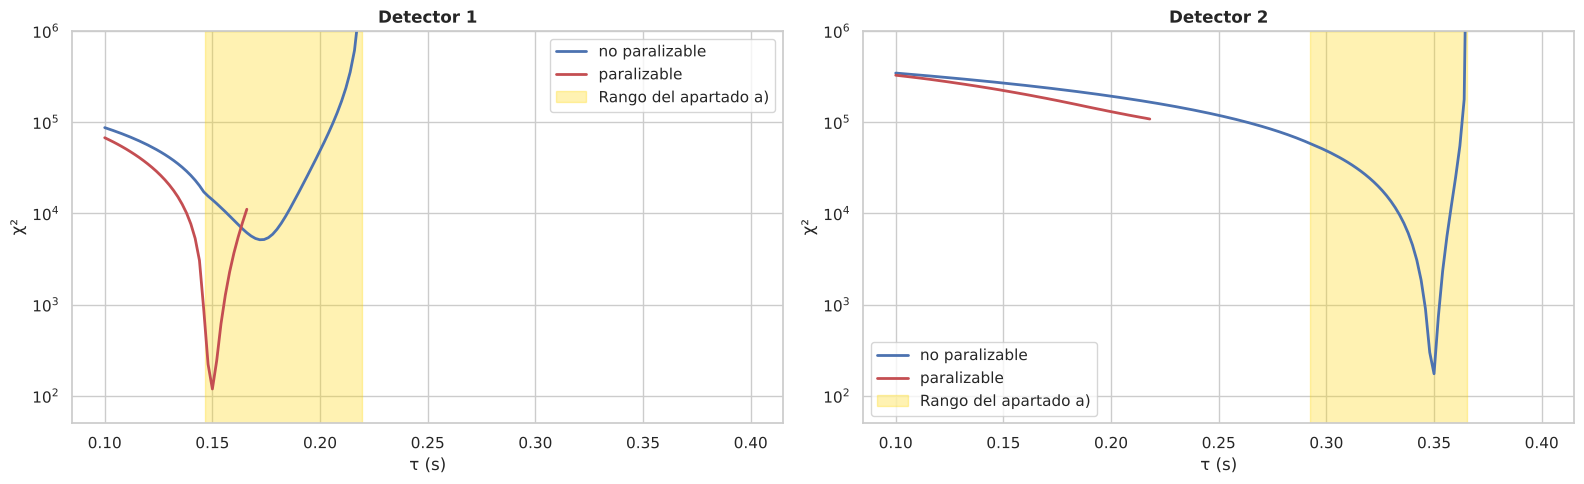

In [ ]:
def histograma_modelo(tau, Am, Nm_total, tipo, mult=10, semilla=123):
    # Histograma esperado de intervalos registrados para un modelo de tiempo muerto
    if tipo == 'no paralizable':
        Av = Am / (1 - Am * tau)
        cdf = lambda x: np.where(x > tau, 1 - np.exp(-Av * (x - tau)), 0.0)
        return Nm_total * np.diff(cdf(bordes)), Av
    # paralizable: rama de baja actividad de Am = Av exp(-Av tau) (requiere Am < 1/(e·tau))
    Av = brentq(lambda A: A * np.exp(-A * tau) - Am, Am, 1 / tau)
    g = np.random.default_rng(semilla)
    T = Nm_total / Am * mult
    tv = np.sort(g.uniform(0, T, g.poisson(Av * T)))
    tr = simular_tiempo_muerto(tv, tau, 'paralizable')
    h, _ = np.histogram(np.diff(tr), bordes)
    return h / mult, Av

def chi2(h_modelo, N):
    m = (N > 0) | (h_modelo > 0.5)
    return np.sum((N[m] - h_modelo[m])**2 / np.maximum(h_modelo[m], 1.0))

taus = np.arange(0.10, 0.40, 0.002)
scan = {}
print("=====================================================================")
print("        AJUSTE χ² DE LOS DOS MODELOS DE TIEMPO MUERTO                 ")
print("=====================================================================")
for nombre, r in res_p9.items():
    scan[nombre] = {}
    for tipo in ['no paralizable', 'paralizable']:
        valores = []
        for tau in taus:
            try:
                h, Av = histograma_modelo(tau, r['Am'], r['Nm'], tipo)
                valores.append((tau, chi2(h, r['N']), Av))
            except ValueError:            # el modelo paralizable no puede dar esa A_m
                pass
        valores = np.array(valores)
        scan[nombre][tipo] = valores
        i = np.argmin(valores[:, 1])
        print(f"{nombre} | {tipo:<15}: τ = {valores[i,0]:.3f} s,  A_v = {valores[i,2]:.3f} s⁻¹,  "
              f"χ²_min = {valores[i,1]:10.1f}  ({len(t_c)} bins)")
print("=====================================================================")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, nombre in zip(axes, res_p9):
    for tipo, color in [('no paralizable', '#4c72b0'), ('paralizable', '#c44e52')]:
        v = scan[nombre][tipo]
        ax.plot(v[:, 0], v[:, 1], color=color, lw=2, label=tipo)
    ax.axvspan(*res_p9[nombre]['rango'], color='gold', alpha=0.3, label='Rango del apartado a)')
    ax.set_yscale('log'); ax.set_ylim(50, 1e6); ax.set_xlabel('τ (s)'); ax.set_ylabel('χ²')
    ax.set_title(f'{nombre}', fontweight='bold'); ax.legend()
plt.tight_layout(); plt.show()

#### **Bonus: Laboratorio virtual de tiempo muerto**

Ajusta "a mano" el modelo a los datos de cada detector: elige el tipo de tiempo muerto y el valor de $\tau$ y observa la calidad del acuerdo (el valor de $A_v$ se fija automáticamente para reproducir la tasa medida). El panel inferior muestra los **residuos normalizados** $(N_{datos} - N_{modelo})/\sqrt{N_{modelo}}$, que deberían fluctuar aleatoriamente entre $\pm 2$ si el modelo es correcto.

**Cuestiones:**
1. Para el detector 1, prueba el modelo no paralizable con $\tau = 0.21$ s. ¿Dónde fallan sistemáticamente los residuos?
2. ¿Por qué no se puede ajustar el detector 2 con un modelo paralizable de $\tau = 0.35$ s? (Pista: máximo de $A_m$ en el Problema 7).
3. ¿Cuál es la sensibilidad del $\chi^2$ a cambios de $\tau$ de 0.005 s? ¿Con qué precisión se determina $\tau$?

In [ ]:
def laboratorio_tiempo_muerto(detector, tipo, tau):
    r = res_p9[detector]
    try:
        h, Av = histograma_modelo(tau, r['Am'], r['Nm'], tipo, mult=5)
    except ValueError:
        print(f"⚠️ Con un tiempo muerto paralizable de τ = {tau:.3f} s la tasa medida no puede superar "
              f"1/(eτ) = {1/(np.e*tau):.2f} s⁻¹ < A_m = {r['Am']:.2f} s⁻¹. Modelo imposible.")
        return
    N = r['N']
    fig, axes = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]})
    ax = axes[0]
    m = N > 0
    ax.errorbar(t_c[m], N[m], yerr=np.sqrt(N[m]), fmt='o', ms=4, color='k', label='Datos')
    ax.step(bordes[:-1], h, where='post', color='#c44e52' if tipo == 'paralizable' else '#4c72b0', lw=2,
            label=f'Modelo {tipo}: τ = {tau:.3f} s, A_v = {Av:.2f} s⁻¹')
    ax.set_yscale('log'); ax.set_ylim(0.5, 2e5); ax.set_ylabel('N')
    ax.set_title(f'{detector}:  χ² = {chi2(h, N):.0f} para {len(t_c)} bins', fontweight='bold')
    ax.legend()
    ax = axes[1]
    ok = h > 0.5
    res = np.zeros_like(h); res[ok] = (N[ok] - h[ok]) / np.sqrt(h[ok])
    ax.bar(t_c, np.clip(res, -20, 20), width=ancho * 0.9, color='#8172b3')
    ax.axhspan(-2, 2, color='green', alpha=0.1)
    ax.set_ylim(-20, 20); ax.set_xlim(0, 3.7)
    ax.set_xlabel('t (s)'); ax.set_ylabel('Residuo (σ)')
    plt.tight_layout(); plt.show()

interact(laboratorio_tiempo_muerto,
         detector=widgets.ToggleButtons(options=['Detector 1', 'Detector 2'], description='Detector'),
         tipo=widgets.ToggleButtons(options=['no paralizable', 'paralizable'], description='Modelo'),
         tau=widgets.FloatSlider(value=0.20, min=0.10, max=0.40, step=0.005, readout_format='.3f',
                                 description='τ (s)', continuous_update=False));

### **Problema 10** *(no esencial)*
Con un detector sin tiempo muerto se hace una medida de la actividad de una fuente detectando 6738 partículas en un tiempo de 3600 s. Con esta información se quiere usar este conjunto detector-fuente como un reloj. Estimar la incertidumbre en la medida de un intervalo de 1 hora, de 1 minuto y de 10 horas.

---

#### **Idea: un "reloj radiactivo"**
Para medir un intervalo de tiempo $t$ contamos partículas hasta registrar $m = A\,t$ sucesos. El tiempo hasta el $m$-ésimo suceso de un proceso de Poisson sigue la **distribución de Erlang** (gamma):
$$ P(t)\,dt = \frac{A^m t^{m-1}}{(m-1)!}e^{-At}\,dt, \qquad \langle t\rangle = \frac{m}{A}, \qquad \sigma(t) = \frac{\sqrt{m}}{A}, \qquad \frac{\sigma(t)}{\langle t\rangle} = \frac{1}{\sqrt{m}} $$

#### **a) Incertidumbre estadística (despreciando el error de $A$)**
Con $A = 6738$ h⁻¹ $= 112.3$ min⁻¹:

| Intervalo | $m = A\,t$ | $\sigma(t) = \sqrt{m}/A$ | Relativa |
| :--- | :---: | :---: | :---: |
| 1 h | 6738 | $1.22\times10^{-2}$ h = **44 s** | 1.2 % |
| 10 h | 67380 | $3.85\times10^{-2}$ h = **2.3 min** | 0.39 % |
| 1 min | 112 | **5.7 s** | 9.4 % |

#### **b) Incertidumbre sistemática (por el error de $A$)**
La actividad sólo se conoce con una precisión $\Delta A/A = 1/\sqrt{6738} = 1.22\%$. Como $t = m/A$, este error se traslada **proporcionalmente** a todos los intervalos: $\Delta t = t\,\Delta A/A$:
* 1 h: $\pm 44$ s; 10 h: $\pm 7.3$ min; 1 min: $\pm 0.7$ s.

| Intervalo | Resultado | Estadístico ± sistemático |
| :--- | :--- | :---: |
| 1 h | $1\text{ h} \pm 44\text{ s} \pm 44\text{ s}$ | $\pm 1.2\% \pm 1.2\%$ |
| 10 h | $10\text{ h} \pm 2.3\text{ min} \pm 7.3\text{ min}$ | $\pm 0.4\% \pm 1.2\%$ |
| 1 min | $1\text{ min} \pm 5.7\text{ s} \pm 0.7\text{ s}$ | $\pm 9.4\% \pm 1.2\%$ |

> El error estadístico disminuye con la duración del intervalo, pero el sistemático (calibración del "reloj") es siempre del 1.2 %: **para intervalos largos domina la calibración**.

In [ ]:
# =====================================================================
# 1. DATOS Y CÁLCULOS
# =====================================================================
n_cal, t_cal = 6738, 3600.0          # calibración del reloj
A_reloj = n_cal / t_cal               # s^-1
dA_rel = 1 / np.sqrt(n_cal)

print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 10)                   ")
print("=====================================================================")
print(f"A = {A_reloj*3600:.0f} h⁻¹ = {A_reloj*60:.1f} min⁻¹,   ΔA/A = {100*dA_rel:.2f}%")
print("-" * 69)
print(f"{'Intervalo':>10} | {'m':>7} | {'σ estadística':>14} | {'σ sistemática':>14} | {'rel. est.':>9}")
print("-" * 69)
for nombre, t in [('1 h', 3600.0), ('10 h', 36000.0), ('1 min', 60.0)]:
    m = A_reloj * t
    s_est = np.sqrt(m) / A_reloj
    s_sis = t * dA_rel
    print(f"{nombre:>10} | {m:7.0f} | {s_est:11.1f} s  | {s_sis:11.1f} s  | {100*s_est/t:8.2f}%")
print("=====================================================================")

# =====================================================================
# 2. COMPROBACIÓN MONTE CARLO: tiempo hasta el m-ésimo suceso
# =====================================================================
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (nombre, t) in zip(axes, [('1 min', 60.0), ('1 h', 3600.0), ('10 h', 36000.0)]):
    m = int(round(A_reloj * t))
    t_m = rng.gamma(shape=m, scale=1 / A_reloj, size=50000)       # suma de m intervalos exponenciales
    ax.hist(t_m, bins=80, density=True, color='#4c72b0', alpha=0.6, label='Monte Carlo')
    x = np.linspace(t_m.min(), t_m.max(), 400)
    ax.plot(x, stats.gamma.pdf(x, a=m, scale=1 / A_reloj), color='#c44e52', lw=2, label='Erlang')
    ax.set_title(f'{nombre}: m = {m},  σ(t) = {t_m.std():.1f} s', fontweight='bold')
    ax.set_xlabel('Tiempo hasta el m-ésimo suceso (s)'); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

### **Problema 11**
Se usan dos plásticos centelleadores idénticos de 100 cm² para medir el flujo de muones cósmicos mediante la técnica de coincidencias. Cada partícula detectada en el primer centelleador activa una ventana de coincidencias de 10 microsegundos. Si se registra una partícula en el segundo detector dentro de esta ventana temporal, entonces el sistema registra una coincidencia. Los muones pueden atravesar ambos centelleadores produciendo coincidencias, mientras que las partículas del fondo ambiental (electrones) sólo pueden interaccionar en uno de los dos. No obstante, si dos partículas interaccionan cada una en un centelleador con una diferencia temporal inferior a 10 microsegundos, también producen una coincidencia "accidental".

**a)** Sabiendo que cada detector por separado registra una frecuencia media de 1000 partículas por segundo, calcular la media y desviación típica del número de coincidencias accidentales que se registrarían en 1 hora.

**b)** Teniendo en cuenta la geometría del sistema y la distribución angular de los muones cósmicos, se ha determinado que el 50 % de los muones que atraviesan el primer centelleador también atraviesan el segundo. Calcular el flujo de muones, y su incertidumbre, sobre el primer centelleador si se ha registrado un total de 183541 coincidencias en una hora.

**c)** ¿Cuánto se reduciría la incertidumbre relativa del flujo de muones si la ventana de coincidencias fuese de 1 microsegundo?

---

#### **a) Coincidencias accidentales en 1 hora**
$A_1 = A_2 = 1000$ s⁻¹, $\tau_c = 10\ \mu$s. En una hora el detector 1 abre $N_1 = A_1 \cdot 3600\text{ s} = 3.6\times10^6$ ventanas. En cada una, el número medio de partículas en el detector 2 es $A_2\tau_c = 0.01$, de modo que:
$$ \langle N_{acc}\rangle \approx N_1\,A_2\,\tau_c = 3.6\times10^6 \times 0.01 = \mathbf{36000}, \qquad \sigma(N_{acc}) = \sqrt{36000} \approx \mathbf{190} $$
*Cálculo "exacto":* una ventana produce coincidencia si llega **al menos una** partícula al detector 2: $P = 1 - e^{-A_2\tau_c}$, con lo que $\langle N_{acc}\rangle = N_1(1 - e^{-A_2\tau_c}) = 35821$ (prácticamente igual porque $A_2\tau_c \ll 1$).

#### **b) Flujo de muones**
Las coincidencias registradas son la suma de las de muones verdaderos y las accidentales. El número de muones que atraviesan el detector 1 es:
$$ \langle N_{\mu,1}\rangle = \frac{N_{coinc} - \langle N_{acc}\rangle}{F_{geom}} = \frac{183541 - 36000}{0.5} = 295082 $$
Ambos términos fluctúan independientemente (Poisson), así que:
$$ \sigma(N_{\mu,1}) = \frac{\sqrt{N_{coinc} + \langle N_{acc}\rangle}}{F_{geom}} = \frac{\sqrt{219541}}{0.5} = 937 \quad\Rightarrow\quad N_{\mu,1} = 295100 \pm 900 $$
$$ \phi_{\mu} = \frac{N_{\mu,1}}{t\,S} = \frac{295082}{3600\text{ s}\times100\text{ cm}^2} = \mathbf{(0.8197 \pm 0.0026)\text{ cm}^{-2}\text{ s}^{-1}} \quad (0.32\%) $$
(¡Unos 49 muones por cm² y minuto, del orden del valor típico a nivel del mar, $\sim 1$ cm⁻² min⁻¹ para un detector horizontal!)

#### **c) Ventana de 1 µs**
Las accidentales se reducen en un factor 10: $\langle N_{acc}'\rangle = 3600$ ($\sigma = 60$). El número de coincidencias de muones no cambia, así que se registrarían:
$$ \langle N_{coinc}'\rangle = 183541 - 36000 + 3600 = 151141 $$
$$ \sigma(N_{\mu,1}) = \frac{\sqrt{151141 + 3600}}{0.5} = 787 \quad\Rightarrow\quad \frac{\sigma(\phi)}{\phi} = \mathbf{0.27\%} $$
La incertidumbre relativa sólo baja de 0.32 % a 0.27 %: **no merece la pena reducir la ventana**, porque la incertidumbre está dominada por la estadística de los propios muones.

In [ ]:
# =====================================================================
# 1. DATOS DE ENTRADA
# =====================================================================
A1_c = A2_c = 1000.0      # s^-1
tau_c = 10e-6             # s
t_c11 = 3600.0            # s
S_det = 100.0             # cm²
F_geom = 0.5
N_coinc = 183541

# =====================================================================
# 2. CÁLCULOS
# =====================================================================
def analisis_coincidencias(tau_ventana, N_coinc_obs, tau_ref=tau_c):
    N1 = A1_c * t_c11
    N_acc = N1 * A2_c * tau_ventana
    N_acc_exacto = N1 * (1 - np.exp(-A2_c * tau_ventana))
    N_mu_coinc = N_coinc - N1 * A2_c * tau_ref          # coincidencias de muones (independientes de la ventana)
    N_obs = N_mu_coinc + N_acc
    N_mu1 = (N_obs - N_acc) / F_geom
    s_mu1 = np.sqrt(N_obs + N_acc) / F_geom
    phi = N_mu1 / (t_c11 * S_det)
    return dict(N_acc=N_acc, N_acc_exacto=N_acc_exacto, N_obs=N_obs, N_mu1=N_mu1, s_mu1=s_mu1,
                phi=phi, s_phi=s_mu1 / (t_c11 * S_det))

r10 = analisis_coincidencias(10e-6, N_coinc)
r1 = analisis_coincidencias(1e-6, N_coinc)

# =====================================================================
# 3. IMPRESIÓN DE RESULTADOS
# =====================================================================
print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 11)                   ")
print("=====================================================================")
print(f"a) ⟨N_acc⟩ = {r10['N_acc']:.0f} ± {np.sqrt(r10['N_acc']):.0f}   (cálculo exacto: {r10['N_acc_exacto']:.0f})")
print("-" * 69)
print(f"b) N_μ,1 = {r10['N_mu1']:.0f} ± {r10['s_mu1']:.0f}")
print(f"   φ_μ = ({r10['phi']:.4f} ± {r10['s_phi']:.4f}) cm⁻² s⁻¹   ({100*r10['s_phi']/r10['phi']:.2f}%)"
      f"   = {r10['phi']*60:.1f} cm⁻² min⁻¹")
print("-" * 69)
print(f"c) Ventana de 1 µs: ⟨N_acc⟩ = {r1['N_acc']:.0f} ± {np.sqrt(r1['N_acc']):.0f},  N_coinc = {r1['N_obs']:.0f}")
print(f"   N_μ,1 = {r1['N_mu1']:.0f} ± {r1['s_mu1']:.0f}  ->  σ(φ)/φ = {100*r1['s_phi']/r1['phi']:.2f}%")
print("=====================================================================")

# Comprobación Monte Carlo de las accidentales (1 s de datos, repetido)
def mc_accidentales(tau_ventana, n_rep=200, T=1.0):
    cuentas = []
    for _ in range(n_rep):
        t1 = np.sort(rng.uniform(0, T, rng.poisson(A1_c * T)))
        t2 = np.sort(rng.uniform(0, T, rng.poisson(A2_c * T)))
        idx = np.searchsorted(t2, t1)                       # primera partícula del detector 2 tras cada una del 1
        ok = idx < len(t2)
        cuentas.append(np.sum(t2[idx[ok]] - t1[ok] <= tau_ventana))
    return np.mean(cuentas)

print(f"Monte Carlo: accidentales por segundo con τ = 10 µs: {mc_accidentales(10e-6):.2f}  (teoría {A1_c*A2_c*10e-6:.2f})")

#### **Bonus: Diseño de un telescopio de muones**

Ajusta la ventana de coincidencias y la tasa individual de cada detector (que depende del fondo ambiental y del umbral de discriminación) y observa cómo cambian la tasa de accidentales y la incertidumbre en el flujo de muones medido en una hora.

**Cuestiones:**
1. ¿A partir de qué tasa individual las accidentales superan a las coincidencias verdaderas con una ventana de 10 µs?
2. La ventana no puede reducirse indefinidamente: la resolución temporal de un centelleador plástico con su fotomultiplicador es de ~1 ns, y los muones tardan unos ns en recorrer la distancia entre detectores. ¿Qué ventana elegirías?
3. ¿Por qué la incertidumbre tiende a un valor constante para ventanas pequeñas?

In [ ]:
def telescopio_muones(log_tau_s, tasa_individual):
    tau = 10**log_tau_s
    N_mu_coinc = N_coinc - A1_c * t_c11 * A2_c * tau_c       # coincidencias de muones en 1 h (fijo)
    taus = np.logspace(-9, -3, 300)
    N_acc = tasa_individual**2 * t_c11 * taus
    s_rel = np.sqrt(N_mu_coinc + 2 * N_acc) / N_mu_coinc * 100

    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
    ax = axes[0]
    ax.loglog(taus * 1e6, N_acc, color='#c44e52', lw=2.5, label='Accidentales en 1 h')
    ax.axhline(N_mu_coinc, color='#4c72b0', lw=2.5, label='Coincidencias de muones en 1 h')
    ax.axvline(tau * 1e6, color='gray', ls=':')
    ax.set_xlabel('Ventana de coincidencias (µs)'); ax.set_ylabel('Número de coincidencias')
    ax.set_title('Coincidencias verdaderas y accidentales', fontweight='bold'); ax.legend()
    ax = axes[1]
    ax.semilogx(taus * 1e6, s_rel, color='k', lw=2.5)
    s_act = np.sqrt(N_mu_coinc + 2 * tasa_individual**2 * t_c11 * tau) / N_mu_coinc * 100
    ax.plot(tau * 1e6, s_act, 'o', color='gold', mec='k', ms=11)
    ax.axhline(100 / np.sqrt(N_mu_coinc), color='#4c72b0', ls='--', label='Límite: sólo estadística de muones')
    ax.set_xlabel('Ventana de coincidencias (µs)'); ax.set_ylabel('σ(φ)/φ (%)')
    ax.set_title('Incertidumbre relativa del flujo', fontweight='bold'); ax.legend()
    plt.tight_layout(); plt.show()
    N_acc_act = tasa_individual**2 * t_c11 * tau
    print(f"Ventana {tau*1e6:.3g} µs, tasa individual {tasa_individual:.0f} s⁻¹:  accidentales = {N_acc_act:.0f}/h  "
          f"|  σ(φ)/φ = {s_act:.3f}%")

interact(telescopio_muones,
         log_tau_s=widgets.FloatSlider(value=-5, min=-9, max=-3, step=0.1, description='log₁₀ τ (s)',
                                       continuous_update=False),
         tasa_individual=widgets.FloatLogSlider(value=1000, base=10, min=1, max=5, step=0.05,
                                                description='Tasa (s⁻¹)', continuous_update=False));

### **Problema 12**
Un detector de humo se basa en una cámara de ionización con una pequeña cantidad de Am-241 (emisor $\alpha$, $E_\alpha$ = 5.5 MeV). La cámara está abierta y expuesta a la entrada de humo. Mientras no hay humo, la radiación $\alpha$ induce una pequeña corriente en la cámara. Pero cuando hay humo, éste reduce la conductividad de la cámara haciendo que la corriente disminuya significativamente.

**a)** Sabiendo que la energía media para crear un par electrón-ión en aire es $w$ = 33.8 eV y que la actividad $\alpha$ dentro de la cámara es $A$ = 123 partículas/s, estimar la corriente que circula por la cámara, suponiendo que las partículas $\alpha$ dejan toda su energía dentro de la cámara, que se recoge el 100 % de las cargas generadas en su interior y que no hay amplificación interna.

**b)** Estimar el tiempo característico del circuito RC necesario para promediar las fluctuaciones de la corriente debidas a la llegada aleatoria de partículas $\alpha$.

**c)** Estimar las fluctuaciones (en porcentaje) en la carga generada por una partícula $\alpha$. Discutir qué ocurriría con las fluctuaciones en la carga si se aumentara la polarización de la cámara de modo que su multiplicación interna media es $\mu$ con desviación $\sigma$.

---

#### **a) Corriente en la cámara**
Cada partícula $\alpha$ crea en promedio
$$ \langle n\rangle = \frac{E_\alpha}{w} = \frac{5.49\times10^6\text{ eV}}{33.8\text{ eV}} = 1.62\times10^5 \text{ pares electrón-ión} $$
(usamos $E_\alpha = 5.49$ MeV, la energía de la línea principal del Am-241).

Cuando los electrones llegan al ánodo y los iones al cátodo, la carga que circula por el circuito externo **por cada par** es $e$ (teorema de Ramo: la carga inducida por el electrón y la inducida por el ion se suman hasta completar exactamente una carga elemental). Por tanto:
$$ \langle Q_\alpha\rangle = e\,\frac{E_\alpha}{w} = 2.60\times10^{-14}\text{ C}, \qquad I = A\,\langle Q_\alpha\rangle = 123 \times 2.60\times10^{-14} \approx \mathbf{3.2\text{ pA}} $$

> **Nota:** si se cuentan por separado las cargas de electrones e iones ($2e$ por par) se obtiene el doble, $\approx 6.4$ pA. Ese recuento duplica la carga que realmente circula: cada par sólo transporta una carga elemental a través del circuito.

Una corriente de picoamperios: ¡por eso estos detectores necesitan electrónica de muy alta impedancia!

#### **b) Tiempo de integración**
Las partículas $\alpha$ llegan en promedio cada
$$ \langle\Delta t\rangle = \frac{1}{A} = \frac{1}{123\text{ s}^{-1}} \approx 8\text{ ms} $$
Para que la corriente parezca continua, la constante de tiempo del circuito debe promediar muchas llegadas: $RC \gg 8$ ms. Más cuantitativamente (teorema de Campbell), la fluctuación relativa de la corriente filtrada es
$$ \frac{\sigma_I}{I} = \frac{1}{\sqrt{2\,A\,RC}} $$
de modo que para fluctuaciones del 1 % se necesita $RC \approx 1/(2A\cdot10^{-4}) \approx 40$ s, y para el 10 %, $RC \approx 0.4$ s.

#### **c) Fluctuaciones en la carga generada por una partícula $\alpha$**
**Sin amplificación.** Si el número de pares fuese poissoniano:
$$ R = \frac{\sigma(n)}{\langle n\rangle} = \frac{1}{\sqrt{\langle n\rangle}} = \frac{1}{\sqrt{1.62\times10^5}} \approx \mathbf{0.25\%} $$
En realidad $R = \sqrt{F/\langle n\rangle}$ con un **factor de Fano** $F < 1$, porque las ionizaciones no son independientes: la energía total depositada es fija (toda la energía de la $\alpha$). Para gases $F \approx 0.2$, lo que da $R \approx 0.11\%$.

**Con amplificación.** Si cada carga primaria se multiplica por un factor $m_i$ aleatorio de media $\mu$ y varianza $s^2$, la carga total es $N = \sum_{i=1}^{n} m_i$, una suma con un número aleatorio de términos. Calculando $\langle N\rangle$ y $\sigma^2(N)$:
$$ \langle N\rangle = \langle n\rangle\,\mu, \qquad \sigma^2(N) = \langle n\rangle\,\mu^2\left(1 + \frac{s^2}{\mu^2}\right) $$
$$ R = \frac{\sigma(N)}{\langle N\rangle} = \frac{1}{\sqrt{\langle n\rangle}}\sqrt{1 + \frac{s^2}{\mu^2}} \equiv \frac{\sqrt{ENF}}{\sqrt{\langle n\rangle}} $$
donde $ENF = 1 + s^2/\mu^2 > 1$ es el **factor de exceso de ruido**. Conclusiones:
* Una amplificación **ideal** (sin fluctuaciones, $s = 0$) no cambia la resolución: multiplica señal y ruido por igual.
* Una amplificación **real** siempre **empeora** la resolución. Por ejemplo, si la multiplicación es poissoniana con $\mu = s^2 = 5$: $ENF = 1.2$ y $R = 0.25\% \times\sqrt{1.2} = 0.27\%$.

In [ ]:
# =====================================================================
# 1. DATOS DE ENTRADA
# =====================================================================
e = 1.602176634e-19    # C
E_alpha = 5.49e6       # eV
w_aire = 33.8          # eV
A_am = 123.0           # s^-1

# =====================================================================
# 2. CÁLCULOS
# =====================================================================
n_pares = E_alpha / w_aire
Q_alpha = e * n_pares
I_camara = A_am * Q_alpha
dt_medio = 1 / A_am
R_poisson = 1 / np.sqrt(n_pares)
R_fano = np.sqrt(0.2 / n_pares)
ENF = 1 + 5 / 5**2
R_amp = R_poisson * np.sqrt(ENF)

# =====================================================================
# 3. IMPRESIÓN DE RESULTADOS
# =====================================================================
print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 12)                   ")
print("=====================================================================")
print(f"a) Pares por partícula α: {n_pares:.4g}   ->   Q = {Q_alpha:.3e} C")
print(f"   Corriente: I = {I_camara*1e12:.2f} pA   (contando 2e por par: {2*I_camara*1e12:.2f} pA)")
print("-" * 69)
print(f"b) Intervalo medio entre α: {dt_medio*1e3:.1f} ms   ->   RC ≫ {dt_medio*1e3:.0f} ms")
for obj in [0.10, 0.01]:
    print(f"   RC para σ_I/I = {100*obj:.0f}%: {1/(2*A_am*obj**2):.2f} s")
print("-" * 69)
print(f"c) R (Poisson) = {100*R_poisson:.3f}%   |   R (Fano F = 0.2) = {100*R_fano:.3f}%")
print(f"   Con multiplicación μ = s² = 5: ENF = {ENF:.2f}  ->  R = {100*R_amp:.3f}%")
print("=====================================================================")

#### **Bonus: Corriente de la cámara de ionización y filtro RC**

El widget simula la llegada aleatoria (poissoniana) de partículas $\alpha$ a la cámara: cada una deposita un pulso de carga $Q_\alpha$ que el circuito RC convierte en una corriente que decae exponencialmente. Observa cómo, al aumentar $RC$, la corriente se convierte en una señal casi continua de valor $I = A\,Q_\alpha$, y compara la fluctuación medida con la predicción de Campbell.

**Cuestiones:**
1. ¿Qué valor de $RC$ necesitas para que la corriente fluctúe menos de un 10 %? ¿Cuánto tardaría entonces el detector en responder a la entrada de humo?
2. ¿Qué compromiso hay entre la estabilidad de la señal y el tiempo de respuesta de la alarma?

In [ ]:
def camara_ionizacion(RC_ms, actividad):
    RC = RC_ms * 1e-3
    T = max(20 * RC, 2.0)
    dt = min(RC / 20, 1e-3)
    t = np.arange(0, T, dt)
    llegadas = np.sort(rng.uniform(0, T, rng.poisson(actividad * T)))
    pulsos = np.histogram(llegadas, bins=np.append(t, T))[0] * Q_alpha
    # Filtro RC discreto: I(t) = carga recogida convolucionada con exp(-t/RC)/RC
    from scipy.signal import lfilter
    alfa = np.exp(-dt / RC)
    I = lfilter([1 / RC], [1, -alfa], pulsos)
    I *= 1e12       # pA
    I_med = actividad * Q_alpha * 1e12
    estable = t > 5 * RC
    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(t, I, color='#4c72b0', lw=1)
    ax.axhline(I_med, color='#c44e52', ls='--', lw=2, label=f'I = A·Q = {I_med:.2f} pA')
    ax.set_xlabel('t (s)'); ax.set_ylabel('Corriente (pA)')
    ax.set_title(f'Corriente en la cámara con RC = {RC_ms:g} ms y A = {actividad:.0f} s⁻¹', fontweight='bold')
    ax.set_ylim(0, max(3 * I_med, np.percentile(I[estable], 99.5) * 1.1))
    ax.legend(loc='upper right'); plt.tight_layout(); plt.show()
    s_med = I[estable].std() / I[estable].mean() if estable.sum() > 10 else np.nan
    print(f"Fluctuación relativa: simulada {100*s_med:.1f}%   |   Campbell 1/√(2·A·RC) = {100/np.sqrt(2*actividad*RC):.1f}%")

interact(camara_ionizacion,
         RC_ms=widgets.FloatLogSlider(value=10, base=10, min=0, max=3.5, step=0.05, description='RC (ms)',
                                      continuous_update=False),
         actividad=widgets.FloatSlider(value=123, min=10, max=1000, step=1, description='A (s⁻¹)',
                                       continuous_update=False));

### **Problema 13**
Un espectrómetro $\gamma$ basado en un centelleador de NaI(Tl) tiene una resolución energética del 7 % a 1 MeV que varía aproximadamente como $1/\sqrt{E}$. Se conoce además que su eficiencia intrínseca es del 36 % a 0.5 MeV, alcanza un valor mínimo de 15 % a 5 MeV y luego crece con $E$.

**a)** Cuando se detecta un rayo $\gamma$, algunos átomos de yodo del cristal pueden excitarse, produciendo una vacante en su nivel 1s y, a continuación, emitiendo un rayo X de energía $E_X$ = 29 keV. Junto al fotopico de la energía $E$ del rayo $\gamma$, puede observarse un pico a una energía $E - E_X$, debido a que algunos de estos rayos X pueden escapar del detector. Determinar el rango de energías de rayos $\gamma$ para el cual se puede distinguir este pico de escape de rayos X.

**b)** Determinar el rango de energías para el cual se puede distinguir el fotopico de su borde Compton asociado.

**c)** ¿Por qué crece la eficiencia con la energía a partir de 5 MeV? Estimar la relación de intensidades entre el fotopico, el pico de escape simple y el pico de escape doble de fotones de aniquilación para fotones incidentes con energía superior a 5 MeV.

---

#### **Criterio de separación**
Dos picos se pueden distinguir si su separación es mayor que la resolución (FWHM). En términos relativos: $\Delta E/E \ge R(E) = 0.07/\sqrt{E/\text{MeV}}$.

#### **a) Pico de escape de rayos X del yodo**
La separación es $E_X = 29$ keV:
$$ \frac{E_X}{E} \ge \frac{0.07}{\sqrt{E}} \quad\Longrightarrow\quad \sqrt{E} \le \frac{E_X}{0.07} = 0.414\ \text{MeV}^{1/2} \quad\Longrightarrow\quad \mathbf{E \lesssim 0.17\text{ MeV}} $$
El pico de escape de rayos X sólo se distingue a **bajas energías** (por debajo de unos 170 keV), donde la diferencia de 29 keV es grande comparada con la anchura del fotopico. Además, sólo a baja energía la interacción ocurre cerca de la superficie del cristal y el rayo X tiene probabilidad apreciable de escapar.

#### **b) Fotopico y borde Compton**
El borde Compton está a $E_{borde} = E\,\dfrac{2\gamma}{1+2\gamma}$, con $\gamma = E/m_ec^2$. Su separación relativa al fotopico es:
$$ \frac{E - E_{borde}}{E} = 1 - \frac{2\gamma}{1+2\gamma} = \frac{m_ec^2}{m_ec^2 + 2E} $$
Imponiendo $\dfrac{m_ec^2}{m_ec^2 + 2E} \ge \dfrac{0.07}{\sqrt{E}}$ y resolviendo numéricamente: $\mathbf{E \lesssim 13\text{ MeV}}$. (A altas energías el borde Compton se acerca al fotopico más deprisa que lo que mejora la resolución: $E - E_{borde} \to m_ec^2/2 = 256$ keV).

#### **c) Eficiencia a alta energía y picos de escape**
Por encima de unos 5 MeV la **creación de pares** domina en el NaI y su sección eficaz crece con la energía, por lo que la eficiencia aumenta.

Tras la creación de pares, el positrón se frena y se aniquila produciendo **dos fotones de 511 keV**, que pueden ser absorbidos o escapar. Suponiendo que la interacción es por creación de pares y que cada fotón de 511 keV se absorbe con probabilidad $\eta(0.5\text{ MeV}) \approx 0.36$, independientemente del otro (**distribución binomial**):
* **Fotopico** (se absorben los dos): $P = 0.36^2 = 0.13$
* **Escape simple** (escapa uno, $E - 511$ keV): $P = 2\times0.36\times0.64 = 0.46$
* **Escape doble** (escapan los dos, $E - 1022$ keV): $P = 0.64^2 = 0.41$

**Relación de intensidades fotopico : escape simple : escape doble ≈ 0.13 : 0.46 : 0.41**

(Es una estimación muy simplificada: en realidad los fotones de aniquilación se generan dentro del cristal, por lo que su probabilidad de absorción depende del tamaño del cristal y de la posición; además, parte de los fotones de aniquilación se absorben sólo parcialmente por efecto Compton.)

In [ ]:
# =====================================================================
# 1. DATOS DE ENTRADA
# =====================================================================
R1 = 0.07           # resolución a 1 MeV
E_X = 0.029         # MeV
me = 0.511          # MeV
eta_511 = 0.36      # eficiencia a ~0.5 MeV

R_NaI = lambda E: R1 / np.sqrt(E)

# =====================================================================
# 2. CÁLCULOS
# =====================================================================
E_max_a = (E_X / R1)**2
E_max_b = brentq(lambda E: me / (me + 2 * E) - R_NaI(E), 0.5, 50)
P_foto = eta_511**2
P_simple = 2 * eta_511 * (1 - eta_511)
P_doble = (1 - eta_511)**2

# =====================================================================
# 3. IMPRESIÓN DE RESULTADOS
# =====================================================================
print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 13)                   ")
print("=====================================================================")
print(f"a) Pico de escape de rayos X distinguible para E ≤ {E_max_a*1e3:.0f} keV")
print(f"b) Borde Compton distinguible del fotopico para E ≤ {E_max_b:.1f} MeV")
print(f"c) Fotopico : escape simple : escape doble = {P_foto:.2f} : {P_simple:.2f} : {P_doble:.2f}"
      f"   (suma = {P_foto+P_simple+P_doble:.2f})")
print("=====================================================================")

E = np.logspace(-2, np.log10(30), 500)
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.loglog(E, R_NaI(E), color='k', lw=2.5, label='Resolución NaI: 0.07/√E')
ax.loglog(E, E_X / E, color='#4c72b0', lw=2, label='Separación relativa escape X: E_X/E')
ax.loglog(E, me / (me + 2 * E), color='#c44e52', lw=2, label='Separación relativa borde Compton')
ax.axvline(E_max_a, color='#4c72b0', ls=':'); ax.axvline(E_max_b, color='#c44e52', ls=':')
ax.text(E_max_a * 1.1, 0.5, f'{E_max_a*1e3:.0f} keV', color='#4c72b0')
ax.text(E_max_b * 1.1, 0.5, f'{E_max_b:.1f} MeV', color='#c44e52')
ax.set_xlabel('E (MeV)'); ax.set_ylabel('ΔE / E')
ax.set_title('Picos distinguibles cuando la separación supera la resolución', fontweight='bold')
ax.legend(loc='lower left'); plt.tight_layout(); plt.show()

#### **Bonus: Espectro simulado de un detector de NaI(Tl)**

Este widget genera un espectro **ilustrativo** de un detector de NaI(Tl) para fotones monoenergéticos, combinando sus componentes principales, todas ellas convolucionadas con la resolución $R(E) = 7\%/\sqrt{E}$:
* **Fotopico** en $E$.
* **Continuo Compton** (Klein-Nishina) hasta el **borde Compton**.
* **Pico de escape de rayos X** del yodo en $E - 29$ keV (sólo relevante a baja energía).
* **Picos de escape simple y doble** en $E - 511$ y $E - 1022$ keV (por encima del umbral de creación de pares), con las intensidades relativas del apartado c).

Las proporciones entre componentes son aproximadas (dependen del tamaño del cristal), pero las **posiciones** y **anchuras** son las del problema.

**Cuestiones:**
1. Comprueba que el pico de escape X sólo se separa del fotopico por debajo de ~170 keV.
2. Comprueba a qué energía el borde Compton "se funde" con el fotopico.
3. ¿Por qué a 10 MeV el pico más intenso puede no ser el fotopico?

In [ ]:
def espectro_NaI(E0, resolucion_1MeV):
    Rf = lambda E: resolucion_1MeV / np.sqrt(np.maximum(E, 1e-3))
    Eb = np.linspace(0.001, E0 * 1.15, 3000)
    dE = Eb[1] - Eb[0]
    def gauss(Ec, area):
        s = Rf(Ec) * Ec / 2.355
        return area * np.exp(-0.5 * ((Eb - Ec) / s)**2) / (np.sqrt(2 * np.pi) * s)
    def suavizar(f):
        # convolución con anchura variable (aproximada por bloques)
        out = np.zeros_like(f)
        for i in np.nonzero(f > 0)[0][::3]:
            s = Rf(Eb[i]) * Eb[i] / 2.355
            out += f[i] * 3 * dE * np.exp(-0.5 * ((Eb - Eb[i]) / s)**2) / (np.sqrt(2 * np.pi) * s)
        return out

    g = E0 / me
    T_borde = E0 * 2 * g / (1 + 2 * g)
    # Klein-Nishina dσ/dT
    T = np.clip(Eb, 1e-6, None); Ep = E0 - T
    cos = 1 - (1 / g) * T / np.maximum(Ep, 1e-9)
    kn = np.where((Eb > 0) & (Eb < T_borde), Ep / E0 + E0 / np.maximum(Ep, 1e-9) - (1 - cos**2), 0)
    kn = kn / (kn.sum() * dE)

    # Fracciones aproximadas (ilustrativas)
    f_foto = np.clip(0.9 * np.exp(-E0 / 0.6), 0.08, 0.9)
    f_par = np.clip(0.6 * np.log(E0 / 1.022) / np.log(10 / 1.022), 0, 0.6) if E0 > 1.022 else 0
    f_comp = 1 - f_foto - f_par
    f_escX = 0.12 * f_foto if E0 > 0.0332 else 0     # escape de rayos X K del yodo

    espectro = suavizar(f_comp * kn)
    espectro += gauss(E0, f_foto * (1 - 0.12 if f_escX else 1))
    if f_escX:
        espectro += gauss(E0 - E_X, f_escX)
    if f_par > 0:
        espectro += gauss(E0, f_par * P_foto) + gauss(E0 - me, f_par * P_simple) + gauss(E0 - 2 * me, f_par * P_doble)

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(Eb * 1e3, espectro, color='#4c72b0', lw=1.8)
    ax.fill_between(Eb * 1e3, espectro, color='#4c72b0', alpha=0.15)
    marcas = [(E0, 'Fotopico'), (T_borde, 'Borde Compton')]
    if E0 < 1.0: marcas.append((E0 - E_X, 'Escape X'))
    if E0 > 1.022: marcas += [(E0 - me, 'Escape simple'), (E0 - 2 * me, 'Escape doble')]
    ymax = espectro.max()
    for Em, nombre in marcas:
        ax.axvline(Em * 1e3, color='gray', ls=':', lw=1)
        ax.text(Em * 1e3, ymax * 1.02, nombre, rotation=90, va='bottom', ha='right', fontsize=8)
    ax.set_ylim(0, ymax * 1.35); ax.set_xlim(0, E0 * 1.15e3)
    ax.set_xlabel('Energía depositada (keV)'); ax.set_ylabel('Cuentas (u. arb.)')
    ax.set_title(f'Espectro simulado de NaI(Tl) para fotones de {E0*1e3:.0f} keV '
                 f'(FWHM = {Rf(E0)*E0*1e3:.0f} keV)', fontweight='bold')
    plt.tight_layout(); plt.show()

interact(espectro_NaI,
         E0=widgets.FloatLogSlider(value=0.662, base=10, min=-1.3, max=1.3, step=0.01, description='E₀ (MeV)',
                                   continuous_update=False),
         resolucion_1MeV=widgets.FloatSlider(value=0.07, min=0.02, max=0.12, step=0.005,
                                             description='R(1 MeV)', continuous_update=False));

### **Problema 14**
Un detector de Germanio con geometría plana tiene un factor de Fano $F$ = 0,10, se conecta a un sistema de procesamiento de pulsos que produce un pico con un ancho a media altura (FWHM) equivalente a 1.2 keV a partir de una entrada de generador de pulsos. Estime la resolución energética del sistema detector-electrónica para rayos gamma incidentes de 140 keV.

---

#### **1. Contribuciones a la resolución**
La dispersión en la energía medida tiene dos contribuciones independientes, que se suman en cuadratura:
$$ \sigma^2 = \sigma_{Ge}^2 + \sigma_{elec}^2 $$
* **Electrónica:** medida directamente con un generador de pulsos (que inyecta siempre la misma carga): $\text{FWHM}_{elec} = 1.2$ keV.
* **Estadística del detector:** el número de pares electrón-hueco creados es $n = E/w$, con $w \approx 3.0$ eV en germanio, y su varianza es $F\,n$ (factor de Fano):
$$ \text{FWHM}_{Ge} = 2.35\sqrt{F\,w\,E} $$

#### **2. Cálculo para $E = 140$ keV**
$$ \text{FWHM}_{Ge} = 2.35\sqrt{0.10\times3.0\text{ eV}\times1.4\times10^5\text{ eV}} = 2.35\times205\text{ eV} = 0.48\text{ keV} $$
$$ \text{FWHM} = \sqrt{0.48^2 + 1.2^2}\text{ keV} = 1.29\text{ keV} $$
$$ R = \frac{\text{FWHM}}{E} = \sqrt{2.35^2\frac{F\,w}{E} + \left(\frac{\text{FWHM}_{elec}}{E}\right)^2} = \sqrt{1.18\times10^{-5} + 7.35\times10^{-5}} = \mathbf{9.2\times10^{-3}} \;(0.92\%) $$

> A esta energía **domina el ruido electrónico**. Compárese con un NaI(Tl) (Problema 13): $R(140\text{ keV}) = 7\%/\sqrt{0.14} \approx 19\%$, ¡unas 20 veces peor! La razón es que en el germanio se necesitan sólo 3 eV por par (frente a los ~100 eV por fotoelectrón efectivo de un centelleador con fotomultiplicador) y además $F \approx 0.1$.

In [ ]:
# =====================================================================
# 1. DATOS DE ENTRADA
# =====================================================================
F_Ge = 0.10
w_Ge = 3.0            # eV por par electrón-hueco
FWHM_elec = 1.2e3     # eV
E_g = 140e3           # eV

# =====================================================================
# 2. CÁLCULOS
# =====================================================================
FWHM_Ge = 2.35 * np.sqrt(F_Ge * w_Ge * E_g)
FWHM_tot = np.hypot(FWHM_Ge, FWHM_elec)
R_tot = FWHM_tot / E_g

print("=====================================================================")
print("                RESULTADOS NUMÉRICOS (PROBLEMA 14)                   ")
print("=====================================================================")
print(f"Pares creados: n = E/w = {E_g/w_Ge:.3g}")
print(f"FWHM estadística (Ge): {FWHM_Ge:.0f} eV   ->  (2.35²Fw/E = {(FWHM_Ge/E_g)**2:.3e})")
print(f"FWHM electrónica:      {FWHM_elec:.0f} eV   ->  ((FWHM_el/E)² = {(FWHM_elec/E_g)**2:.3e})")
print(f"FWHM total:            {FWHM_tot:.0f} eV")
print(f"Resolución R = {R_tot:.2e}  ({100*R_tot:.2f}%)")
print(f"Comparación NaI(Tl) a 140 keV: R = {100*0.07/np.sqrt(0.14):.1f}%")
print("=====================================================================")

#### **Bonus: Germanio frente a NaI(Tl)**

El widget muestra la resolución de un detector de germanio (estadística + electrónica) en función de la energía, comparada con la de un NaI(Tl), y simula el aspecto de un fotopico en ambos detectores.

**Cuestiones:**
1. ¿A partir de qué energía domina la contribución estadística del germanio sobre la electrónica de 1.2 keV?
2. Con el NaI de 7 % a 1 MeV, ¿podrías separar las dos líneas del $^{60}$Co (1173 y 1332 keV)? ¿Y las líneas de 1173 keV y 1186 keV?
3. ¿Qué factor de Fano tendría que tener el germanio para que, sin ruido electrónico, su resolución fuera igual a la del NaI?

In [ ]:
def germanio_vs_NaI(E_keV, FWHM_el_keV, Fano):
    E = np.logspace(1, 4, 400)          # keV
    fw_ge_stat = 2.35 * np.sqrt(Fano * w_Ge * E * 1e3) / 1e3     # keV
    fw_ge = np.hypot(fw_ge_stat, FWHM_el_keV)
    fw_nai = 0.07 * np.sqrt(E / 1e3) * 1e3                       # keV  (R·E con R = 0.07/√E[MeV])

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    ax = axes[0]
    ax.loglog(E, fw_nai / E * 100, color='#dd8452', lw=2.5, label='NaI(Tl): 7%/√E')
    ax.loglog(E, fw_ge / E * 100, color='#4c72b0', lw=2.5, label='Ge total')
    ax.loglog(E, fw_ge_stat / E * 100, color='#4c72b0', ls=':', lw=1.5, label='Ge (sólo estadística)')
    ax.loglog(E, FWHM_el_keV / E * 100, color='gray', ls='--', lw=1.5, label='Electrónica')
    ax.axvline(E_keV, color='k', ls=':', lw=1)
    ax.set_xlabel('E (keV)'); ax.set_ylabel('Resolución FWHM/E (%)')
    ax.set_title('Resolución energética', fontweight='bold'); ax.legend(fontsize=9)

    ax = axes[1]
    fw_g = np.hypot(2.35 * np.sqrt(Fano * w_Ge * E_keV * 1e3) / 1e3, FWHM_el_keV)
    fw_n = 0.07 * np.sqrt(E_keV / 1e3) * 1e3
    x = np.linspace(max(0.0, E_keV - 3 * fw_n), E_keV + 3 * fw_n, 1000)
    for fw, color, nombre in [(fw_n, '#dd8452', 'NaI(Tl)'), (fw_g, '#4c72b0', 'Ge')]:
        s = fw / 2.355
        ax.plot(x, np.exp(-0.5 * ((x - E_keV) / s)**2) / (np.sqrt(2 * np.pi) * s), color=color, lw=2.5,
                label=f'{nombre}: FWHM = {fw:.2f} keV ({100*fw/E_keV:.2f}%)')
    ax.set_xlabel('Energía (keV)'); ax.set_ylabel('Densidad (área = 1)')
    ax.set_title(f'Fotopico de {E_keV:.0f} keV', fontweight='bold'); ax.legend(fontsize=9)
    plt.tight_layout(); plt.show()

interact(germanio_vs_NaI,
         E_keV=widgets.FloatLogSlider(value=140, base=10, min=1, max=4, step=0.02, description='E (keV)',
                                      continuous_update=False),
         FWHM_el_keV=widgets.FloatSlider(value=1.2, min=0.2, max=3.0, step=0.1, description='FWHM el. (keV)',
                                         continuous_update=False),
         Fano=widgets.FloatSlider(value=0.10, min=0.05, max=1.0, step=0.01, description='Fano F',
                                  continuous_update=False));